# Expert Ratings Analysis of DC Proposals

This notebook analyses evaluations of five proposals (P1–P5) by 13 experts: five aware of the proposals’ LLM origin and eight blind to that information. The broader study workflow is described in [README.md].

The analysis covers:

1. Survey-data preparation and expert-profile summaries.
2. Proposal judgeability by condition, including written explanations for inability to judge.
3. Descriptive distributions of novelty drivers, previous exposure, novelty, perceived difference, and confidence.
4. Proposal-specific novelty–difference associations using Kendall’s tau-b, bootstrap confidence intervals, permutation tests, and Holm correction.
5. Proposal-specific aware–blind comparisons using Mann–Whitney U, rank-biserial effect sizes with bootstrap confidence intervals, exact permutation tests, and Holm correction within each outcome.

Rating analyses retain responses from experts who could judge the relevant proposal. Given the small samples, inferential findings are exploratory and interpreted alongside effect sizes and uncertainty. Tables and figures are exported for manuscript reporting.

In [2]:
# Cell 1: imports
from __future__ import annotations

from itertools import combinations
from pathlib import Path
from textwrap import fill, shorten
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from IPython.display import Markdown, display
from matplotlib.lines import Line2D
from scipy.stats import kendalltau
from itertools import combinations
import warnings

from scipy.stats import rankdata

In [3]:
# Data preparation
def locate_survey_files():
    """Locate the expertsRatings directory and survey files."""
    current_dir = Path.cwd().resolve()

    candidate_dirs = [
        current_dir,
        current_dir / "expertsRatings",
        current_dir / "EICS-2026" / "expertsRatings",
        current_dir.parent / "expertsRatings",
    ]

    for directory in candidate_dirs:
        if not directory.exists():
            continue

        aware_files = sorted(directory.glob("Aware-*.xlsx"))
        blind_files = sorted(directory.glob("Blind-*.xlsx"))

        if len(aware_files) == 1 and len(blind_files) == 1:
            return directory, aware_files[0], blind_files[0]

    raise FileNotFoundError(
        "The aware and blind survey workbooks could not be located. "
        "Run the notebook from EICS-2026 or "
        "EICS-2026/expertsRatings."
    )


def clean_text(value):
    """Normalize whitespace and empty text values."""
    if pd.isna(value):
        return pd.NA

    value = str(value).replace("\xa0", " ").strip()
    return value if value else pd.NA


def find_column(columns, prefix):
    """Find one survey column beginning with the given text."""
    matches = [
        column
        for column in columns
        if str(column).startswith(prefix)
    ]

    if len(matches) != 1:
        raise ValueError(
            f"Expected one column beginning with {prefix!r}, "
            f"but found {len(matches)}: {matches}"
        )

    return matches[0]


def load_respondent_data(aware_file, blind_file):
    source_files = [
        {
            "condition": "aware",
            "condition_label": "Aware of LLM origin",
            "expert_suffix": "A",
            "file_path": aware_file,
        },
        {
            "condition": "blind",
            "condition_label": "Blind to LLM origin",
            "expert_suffix": "B",
            "file_path": blind_file,
        },
    ]

    frames = []

    for source in source_files:
        condition = source["condition"]
        condition_label = source["condition_label"]
        expert_suffix = source["expert_suffix"]
        file_path = source["file_path"]

        df = pd.read_excel(file_path)

        # Normalize column headings.
        df.columns = [
            str(column).replace("\xa0", " ").strip()
            for column in df.columns
        ]

        # Normalize text values.
        text_columns = df.select_dtypes(
            include=["object", "string"]
        ).columns

        for column in text_columns:
            df[column] = df[column].map(clean_text)

        consent_column = find_column(
            df.columns,
            "Continue to the form?"
        )
        domain_column = find_column(
            df.columns,
            "Your domain expertise in DC"
        )
        site_column = find_column(
            df.columns,
            "Which part of the demonstration site"
        )
        experience_column = find_column(
            df.columns,
            "Years of experience"
        )

        # Retain only respondents who consented.
        consent_response = (
            df[consent_column]
            .astype("string")
            .str.casefold()
        )

        df = df.loc[
            consent_response.str.startswith("yes", na=False)
        ].copy()

        # Preserve the original order within each workbook.
        df["expert_row_in_file"] = np.arange(1, len(df) + 1)

        df["condition"] = condition
        df["condition_label"] = condition_label
        df["source_file"] = file_path.name

        # Internal identifier used for data processing.
        df["expert_id"] = (
            condition
            + "_"
            + df["expert_row_in_file"].astype(str)
        )

        # Anonymous reporting code:
        # E1A–E5A for aware experts and
        # E1B–E8B for blind experts.
        df["expert_code"] = (
            "E"
            + df["expert_row_in_file"].astype(str)
            + expert_suffix
        )

        # Standardized professional-profile variables.
        df["domain_expertise"] = df[domain_column]
        df["site_expertise_area"] = df[site_column]
        df["years_experience"] = pd.to_numeric(
            df[experience_column],
            errors="coerce",
        )

        frames.append(df)

    # Retain the complete survey data for proposal-level analysis.
    raw_df = pd.concat(
        frames,
        ignore_index=True,
        sort=False,
    )

    # Create one anonymous row per expert.
    respondents_df = (
        raw_df[
            [
                "expert_id",
                "expert_code",
                "condition",
                "condition_label",
                "source_file",
                "expert_row_in_file",
                "domain_expertise",
                "site_expertise_area",
                "years_experience",
            ]
        ]
        .drop_duplicates(subset="expert_id")
        .reset_index(drop=True)
    )

    # Verify that internal and reporting identifiers are unique.
    if not respondents_df["expert_id"].is_unique:
        raise ValueError(
            "The internal expert identifiers are not unique."
        )

    if not respondents_df["expert_code"].is_unique:
        raise ValueError(
            "The anonymous expert codes are not unique."
        )

    return raw_df, respondents_df


# Locate the survey files.
BASE_DIR, AWARE_FILE, BLIND_FILE = locate_survey_files()

# Create the complete and respondent-level datasets.
raw_df, respondents_df = load_respondent_data(
    AWARE_FILE,
    BLIND_FILE,
)


print(f"Data directory: {BASE_DIR}")
print(f"Combined expert sample: {len(respondents_df)} respondents")

print("\nExperts by evaluation condition:")
display(
    respondents_df[
        ["condition_label", "expert_code"]
    ]
    .groupby("condition_label")
    .agg(
        experts=("expert_code", "count"),
        expert_codes=(
            "expert_code",
            lambda values: ", ".join(values),
        ),
    )
    .reset_index()
)

print("\nCombined professional and expertise profile:")
display(
    respondents_df[
        [
            "expert_code",
            "domain_expertise",
            "site_expertise_area",
            "years_experience",
        ]
    ]
)

Data directory: /Users/HP/Documents/EICS-2026/expertsRatings
Combined expert sample: 13 respondents

Experts by evaluation condition:


,condition_label,experts,expert_codes
0,Aware of LLM origin,5,"E1A, E2A, E3A, E4A, E5A"
1,Blind to LLM origin,8,"E1B, E2B, E3B, E4B, E5B, E6B, E7B, E8B"



Combined professional and expertise profile:


,expert_code,domain_expertise,site_expertise_area,years_experience
0,E1A,researcher in ai and energy,Ports,5
1,E2A,engineer,Ports,34
2,E3A,Standardisation Director,Buildings,30
3,E4A,"Electrical engineer, System integrator",Ports,9
4,E5A,Telecom Engineer,Data Centres,11
5,E1B,electronics engineer,Data Centres,12
6,E2B,"Electrical engineer, innovation department of ...",Ports,14
7,E3B,Electrial Engineer,Buildings,2
8,E4B,power electronics engineer,Industry,3
9,E5B,electrical engineer,Buildings,18


In [4]:
# Export the detailed expert profile to LaTeX

expert_profile_export_df = (
    respondents_df
    .assign(
        _condition_order=(
            respondents_df["condition"]
            .map({"aware": 0, "blind": 1})
        )
    )
    .sort_values(
        ["_condition_order", "expert_row_in_file"]
    )
    [
        [
            "expert_code",
            "domain_expertise",
            "site_expertise_area",
            "years_experience",
        ]
    ]
    .copy()
)


# Use publication-friendly column headings.
expert_profile_export_df = (
    expert_profile_export_df.rename(
        columns={
            "expert_code": "Expert code",
            "domain_expertise": "Domain expertise",
            "site_expertise_area": "Site expertise area",
            "years_experience": "Years of experience",
        }
    )
)


# Display years without decimal places.
expert_profile_export_df["Years of experience"] = (
    expert_profile_export_df["Years of experience"]
    .astype("Int64")
)


# Display the table in the notebook.
display(expert_profile_export_df)


# Export the LaTeX table.
TABLE_DIR = BASE_DIR / "outputs" / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)

latex_file = TABLE_DIR / "expert_detailed_profile.tex"

expert_profile_export_df.to_latex(
    buf=latex_file,
    index=False,
    escape=True,
    caption=(
        "Professional and expertise profile of the "
        "participating experts."
    ),
    label="tab:expert_detailed_profile",
    position="htbp",
    column_format=r"lp{7.0cm}p{2.6cm}r",
)

print(f"LaTeX table exported to: {latex_file}")

,Expert code,Domain expertise,Site expertise area,Years of experience
0,E1A,researcher in ai and energy,Ports,5
1,E2A,engineer,Ports,34
2,E3A,Standardisation Director,Buildings,30
3,E4A,"Electrical engineer, System integrator",Ports,9
4,E5A,Telecom Engineer,Data Centres,11
5,E1B,electronics engineer,Data Centres,12
6,E2B,"Electrical engineer, innovation department of ...",Ports,14
7,E3B,Electrial Engineer,Buildings,2
8,E4B,power electronics engineer,Industry,3
9,E5B,electrical engineer,Buildings,18


LaTeX table exported to: /Users/HP/Documents/EICS-2026/expertsRatings/outputs/tables/expert_detailed_profile.tex


In [5]:
# Combined expert-profile summary and LaTeX export

def format_number(value):
    """Remove unnecessary trailing zeros."""
    return f"{value:.1f}".rstrip("0").rstrip(".")


def format_count_percentage(count, total):
    percentage = 100 * count / total
    return f"{count} ({percentage:.1f}\\%)"


n_experts = len(respondents_df)

condition_counts = respondents_df["condition"].value_counts()
site_counts = respondents_df["site_expertise_area"].value_counts()

years = respondents_df["years_experience"].dropna()

expert_profile_table = pd.DataFrame(
    [
        {
            "Characteristic": "Experts, $n$",
            "Combined sample": str(n_experts),
        },
        {
            "Characteristic": "Aware of the generation source",
            "Combined sample": format_count_percentage(
                condition_counts.get("aware", 0),
                n_experts,
            ),
        },
        {
            "Characteristic": "Blind to the generation source",
            "Combined sample": format_count_percentage(
                condition_counts.get("blind", 0),
                n_experts,
            ),
        },
        {
            "Characteristic": "Years of experience, range",
            "Combined sample": (
                f"{format_number(years.min())}--"
                f"{format_number(years.max())}"
            ),
        },
        {
            "Characteristic": "Ports expertise",
            "Combined sample": format_count_percentage(
                site_counts.get("Ports", 0),
                n_experts,
            ),
        },
        {
            "Characteristic": "Buildings expertise",
            "Combined sample": format_count_percentage(
                site_counts.get("Buildings", 0),
                n_experts,
            ),
        },
        {
            "Characteristic": "Industry expertise",
            "Combined sample": format_count_percentage(
                site_counts.get("Industry", 0),
                n_experts,
            ),
        },
        {
            "Characteristic": "Data-centre expertise",
            "Combined sample": format_count_percentage(
                site_counts.get("Data Centres", 0),
                n_experts,
            ),
        },
    ]
)

display(expert_profile_table)

# Export as a LaTeX table.
TABLE_DIR = BASE_DIR / "outputs" / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)

latex_file = TABLE_DIR / "expert_profile_table.tex"

expert_profile_table.to_latex(
    buf=latex_file,
    index=False,
    escape=False,
    column_format="lr",
    caption="Summary of the participating experts.",    
    label="tab:expert_profile",
    position="htbp",
)

print(f"LaTeX table exported to: {latex_file}")

,Characteristic,Combined sample
0,"Experts, $n$",13
1,Aware of the generation source,5 (38.5\%)
2,Blind to the generation source,8 (61.5\%)
3,"Years of experience, range",2--34
4,Ports expertise,4 (30.8\%)
5,Buildings expertise,5 (38.5\%)
6,Industry expertise,2 (15.4\%)
7,Data-centre expertise,2 (15.4\%)


LaTeX table exported to: /Users/HP/Documents/EICS-2026/expertsRatings/outputs/tables/expert_profile_table.tex


In [6]:
# Prepare proposal judgeability data
proposal_questions = [
    {
        "proposal_id": "P1",
        "proposal": "EV charging stations",
        "ability_column": (
            "Based on this description, can you judge the novelty "
            "of the EV charging stations?"
        ),
        "reason_column": "Reason for selecting 'no'",
    },
    {
        "proposal_id": "P2",
        "proposal": (
            "Intelligent building energy management systems (IBEMS)"
        ),
        "ability_column": (
            "Based on this description, can you judge the novelty "
            "of the IBEMS?"
        ),
        "reason_column": "Reason for selecting 'no'2",
    },
    {
        "proposal_id": "P3",
        "proposal": "Solar PV tracking system",
        "ability_column": (
            "Based on this description, can you judge the novelty "
            "of the solar PV tracking system?"
        ),
        "reason_column": "Reason for selecting 'no'3",
    },
    {
        "proposal_id": "P4",
        "proposal": "Battery energy storage systems",
        "ability_column": (
            "Based on this description, can you judge the novelty "
            "of the battery energy storage systems?"
        ),
        "reason_column": "Reason for selecting 'no'4",
    },
    {
        "proposal_id": "P5",
        "proposal": "LED lighting systems",
        "ability_column": (
            "Based on this description, can you judge the novelty "
            "of the LED lighting systems?"
        ),
        "reason_column": "Reason for selecting 'no'5",
    },
]


judgeability_frames = []

for question in proposal_questions:
    required_columns = [
        "expert_id",
        "expert_code",
        "condition",
        "condition_label",
        question["ability_column"],
        question["reason_column"],
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in raw_df.columns
    ]

    if missing_columns:
        raise KeyError(
            f"Missing columns for {question['proposal']}: "
            f"{missing_columns}"
        )

    proposal_df = raw_df[required_columns].copy()

    proposal_df = proposal_df.rename(
        columns={
            question["ability_column"]: "ability_response_raw",
            question["reason_column"]: "reason_unable_to_judge",
        }
    )

    proposal_df["proposal_id"] = question["proposal_id"]
    proposal_df["proposal"] = question["proposal"]

    # Normalize the ability-to-judge response.
    proposal_df["ability_response_raw"] = (
        proposal_df["ability_response_raw"].map(clean_text)
    )

    normalized_response = (
        proposal_df["ability_response_raw"]
        .astype("string")
        .str.casefold()
        .map(
            {
                "yes": "Yes",
                "no": "No",
            }
        )
    )

    # Detect unexpected response values before assigning missingness.
    unrecognized_response = (
        proposal_df["ability_response_raw"].notna()
        & normalized_response.isna()
    )

    if unrecognized_response.any():
        unexpected_values = (
            proposal_df.loc[
                unrecognized_response,
                "ability_response_raw",
            ]
            .drop_duplicates()
            .tolist()
        )

        raise ValueError(
            f"Unexpected ability-to-judge responses for "
            f"{question['proposal']}: {unexpected_values}"
        )

    proposal_df["ability_to_judge"] = (
        normalized_response.fillna("Missing")
    )

    # Clean the written follow-up reason.
    proposal_df["reason_unable_to_judge"] = (
        proposal_df["reason_unable_to_judge"].map(clean_text)
    )

    # Describe whether the follow-up reason is consistent with the
    # ability-to-judge response.
    ability = proposal_df["ability_to_judge"]
    has_reason = proposal_df["reason_unable_to_judge"].notna()

    proposal_df["reason_status"] = np.select(
        [
            ability.eq("No") & has_reason,
            ability.eq("No") & ~has_reason,
            ability.eq("Yes") & ~has_reason,
            ability.eq("Yes") & has_reason,
            ability.eq("Missing") & ~has_reason,
            ability.eq("Missing") & has_reason,
        ],
        [
            "Provided",
            "Missing follow-up reason",
            "Not applicable",
            "Reason recorded after Yes",
            "Ability response missing",
            "Reason recorded without ability response",
        ],
        default="Unclassified",
    )

    judgeability_frames.append(proposal_df)


# One row for every expert–proposal evaluation.
judgeability_df = pd.concat(
    judgeability_frames,
    ignore_index=True,
)

proposal_order = [
    question["proposal"]
    for question in proposal_questions
]

judgeability_df["proposal"] = pd.Categorical(
    judgeability_df["proposal"],
    categories=proposal_order,
    ordered=True,
)

judgeability_df = (
    judgeability_df[
        [
            "expert_id",
            "expert_code",
            "condition",
            "condition_label",
            "proposal_id",
            "proposal",
            "ability_to_judge",
            "reason_unable_to_judge",
            "reason_status",
        ]
    ]
    .sort_values(["expert_id", "proposal_id"])
    .reset_index(drop=True)
)


# Validate the expert–proposal structure.
number_of_experts = respondents_df["expert_id"].nunique()
number_of_proposals = len(proposal_questions)
expected_evaluations = number_of_experts * number_of_proposals

if len(judgeability_df) != expected_evaluations:
    raise ValueError(
        f"Expected {expected_evaluations} expert–proposal "
        f"evaluations, but found {len(judgeability_df)}."
    )

if judgeability_df.duplicated(
    subset=["expert_id", "proposal_id"]
).any():
    raise ValueError(
        "Duplicate expert–proposal evaluations were detected."
    )

print(
    f"Created {len(judgeability_df)} expert–proposal evaluations "
    f"from {number_of_experts} experts and "
    f"{number_of_proposals} proposals."
)
# Validate judgeability responses.
valid_responses = judgeability_df[
    "ability_to_judge"
].isin(["Yes", "No"])

if not valid_responses.all():
    invalid_records = judgeability_df.loc[
        ~valid_responses,
        ["expert_code", "proposal_id", "ability_to_judge"],
    ]

    raise ValueError(
        "Missing or unexpected judgeability responses:\n"
        f"{invalid_records}"
    )


# Create the summary required by the following plotting cell.
judgeability_summary = (
    judgeability_df
    .groupby(
        ["proposal_id", "proposal"],
        observed=True,
        sort=False,
    )
    .agg(
        evaluations=("expert_id", "size"),
        can_judge=(
            "ability_to_judge",
            lambda values: values.eq("Yes").sum(),
        ),
        unable_to_judge=(
            "ability_to_judge",
            lambda values: values.eq("No").sum(),
        ),
        reasons_provided=(
            "reason_status",
            lambda values: values.eq("Provided").sum(),
        ),
        missing_follow_up_reasons=(
            "reason_status",
            lambda values: values.eq(
                "Missing follow-up reason"
            ).sum(),
        ),
    )
    .reset_index()
)

judgeability_summary["can_judge_percentage"] = (
    100
    * judgeability_summary["can_judge"]
    / judgeability_summary["evaluations"]
)

judgeability_summary["unable_to_judge_percentage"] = (
    100
    * judgeability_summary["unable_to_judge"]
    / judgeability_summary["evaluations"]
)

Created 65 expert–proposal evaluations from 13 experts and 5 proposals.


In [7]:
# Written reasons for inability to judge and LaTeX export
unable_to_judge_reasons_df = (
    judgeability_df.loc[
        judgeability_df["ability_to_judge"].eq("No"),
        [
            "expert_code",
            "proposal_id",
            "proposal",
            "reason_unable_to_judge",
            "reason_status",
        ],
    ]
    .copy()
    .reset_index(drop=True)
)

# Display one qualitative-review section per proposal
proposal_reason_tables = {}


for question in proposal_questions:
    proposal_id = question["proposal_id"]
    proposal_name = question["proposal"]

    proposal_reasons = (
        unable_to_judge_reasons_df.loc[
            unable_to_judge_reasons_df[
                "proposal_id"
            ].eq(proposal_id),
            [
                "expert_code",
                "reason_unable_to_judge",
            ],
        ]
        .copy()
        .reset_index(drop=True)
    )

    unable_count = len(proposal_reasons)

    reasons_provided = int(
        proposal_reasons["reason_unable_to_judge"]
        .notna()
        .sum()
    )

    missing_reasons = int(
        proposal_reasons["reason_unable_to_judge"]
        .isna()
        .sum()
    )

    proposal_reasons["reason_unable_to_judge"] = (
        proposal_reasons["reason_unable_to_judge"]
        .fillna("No written reason provided")
    )

    proposal_reasons = proposal_reasons.rename(
        columns={
            "expert_code": "Expert code",
            "reason_unable_to_judge": "Written reason",
        }
    )

    proposal_reason_tables[proposal_id] = {
        "proposal": proposal_name,
        "unable_count": unable_count,
        "reasons_provided": reasons_provided,
        "missing_reasons": missing_reasons,
        "table": proposal_reasons,
    }

    display(
        Markdown(
            f"### {proposal_id} — {proposal_name}\n\n"
            f"**Unable to judge:** {unable_count}  \n"
            f"**Reasons provided:** {reasons_provided}  \n"
            f"**Missing reasons:** {missing_reasons}"
        )
    )

    display(
        proposal_reasons.style
        .hide(axis="index")
        .set_properties(
            subset=["Expert code"],
            **{
                "text-align": "left",
                "vertical-align": "top",
                "min-width": "90px",
            },
        )
        .set_properties(
            subset=["Written reason"],
            **{
                "white-space": "pre-wrap",
                "text-align": "left",
                "vertical-align": "top",
                "min-width": "500px",
                "max-width": "750px",
                "word-wrap": "break-word",
            },
        )
        .set_table_styles(
            [
                {
                    "selector": "th",
                    "props": [
                        ("text-align", "left"),
                        ("vertical-align", "top"),
                    ],
                },
                {
                    "selector": "td",
                    "props": [
                        ("vertical-align", "top"),
                    ],
                },
            ]
        )
    )

# Export the proposal-grouped review to LaTeX
def escape_latex(value):
    """Escape characters with a special meaning in LaTeX."""
    replacements = {
        "\\": r"\textbackslash{}",
        "&": r"\&",
        "%": r"\%",
        "$": r"\$",
        "#": r"\#",
        "_": r"\_",
        "{": r"\{",
        "}": r"\}",
        "~": r"\textasciitilde{}",
        "^": r"\textasciicircum{}",
    }

    text = str(value).replace("\n", " ")

    return "".join(
        replacements.get(character, character)
        for character in text
    )


latex_content = [
    r"% Requires \usepackage{booktabs}",
    r"% Requires \usepackage{tabularx}",
    "",
]


for proposal_id, information in proposal_reason_tables.items():
    proposal_name = information["proposal"]
    unable_count = information["unable_count"]
    reasons_provided = information["reasons_provided"]
    missing_reasons = information["missing_reasons"]
    reason_table = information["table"]

    latex_content.extend(
        [
            (
                r"\subsubsection*{"
                + escape_latex(proposal_id)
                + " -- "
                + escape_latex(proposal_name)
                + "}"
            ),
            (
                r"\noindent "
                r"\textbf{Unable to judge:} "
                + str(unable_count)
                + r"\quad "
                r"\textbf{Reasons provided:} "
                + str(reasons_provided)
                + r"\quad "
                r"\textbf{Missing reasons:} "
                + str(missing_reasons)
            ),
            "",
            r"\begin{tabularx}{\linewidth}{@{}lX@{}}",
            r"\toprule",
            r"Expert code & Written reason \\",
            r"\midrule",
        ]
    )

    for _, response in reason_table.iterrows():
        expert_code = escape_latex(
            response["Expert code"]
        )

        written_reason = escape_latex(
            response["Written reason"]
        )

        latex_content.append(
            f"{expert_code} & {written_reason} \\\\"
        )

    latex_content.extend(
        [
            r"\bottomrule",
            r"\end{tabularx}",
            "",
            r"\medskip",
            "",
        ]
    )


TABLE_DIR = BASE_DIR / "outputs" / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)

latex_file = (
    TABLE_DIR
    / "proposal_grouped_unable_to_judge_reasons.tex"
)

latex_file.write_text(
    "\n".join(latex_content),
    encoding="utf-8",
)

print(f"LaTeX qualitative table exported to: {latex_file}")

### P1 — EV charging stations

**Unable to judge:** 1  
**Reasons provided:** 1  
**Missing reasons:** 0

Expert code,Written reason
E4B,"known technology, known application, maybe some novelty on the optimization part"


### P2 — Intelligent building energy management systems (IBEMS)

**Unable to judge:** 3  
**Reasons provided:** 3  
**Missing reasons:** 0

Expert code,Written reason
E3A,"EMS is already existing. the fact to move to DC will not change so much the approach. Even more, it will reduce the interest of EMS as DC architecture will work as Micorgrid."
E6B,It is to me known and a general description
E7B,"EMS with RESS has been around for quite some time. From the description alone it is not clear where the innovation is (probably in the connection to the DC system, regarding for example Droop Control? But that is a guess and as such I cannot judge the novelty)"


### P3 — Solar PV tracking system

**Unable to judge:** 4  
**Reasons provided:** 4  
**Missing reasons:** 0

...

### P4 — Battery energy storage systems

**Unable to judge:** 0  
**Reasons provided:** 0  
**Missing reasons:** 0

Expert code,Written reason


### P5 — LED lighting systems

**Unable to judge:** 3  
**Reasons provided:** 3  
**Missing reasons:** 0

Expert code,Written reason
E4B,known technology and application
E6B,"LED system, of course well managed, were novelty approx 10 years ago"
E8B,less experience


LaTeX qualitative table exported to: /Users/HP/Documents/EICS-2026/expertsRatings/outputs/tables/proposal_grouped_unable_to_judge_reasons.tex


Figure exported to: /Users/HP/Documents/EICS-2026/expertsRatings/outputs/figures/judgeability_heatmap_with_reasons.eps
Figure exported to: /Users/HP/Documents/EICS-2026/expertsRatings/outputs/figures/judgeability_heatmap_with_reasons.pdf
Figure exported to: /Users/HP/Documents/EICS-2026/expertsRatings/outputs/figures/judgeability_heatmap_with_reasons.png


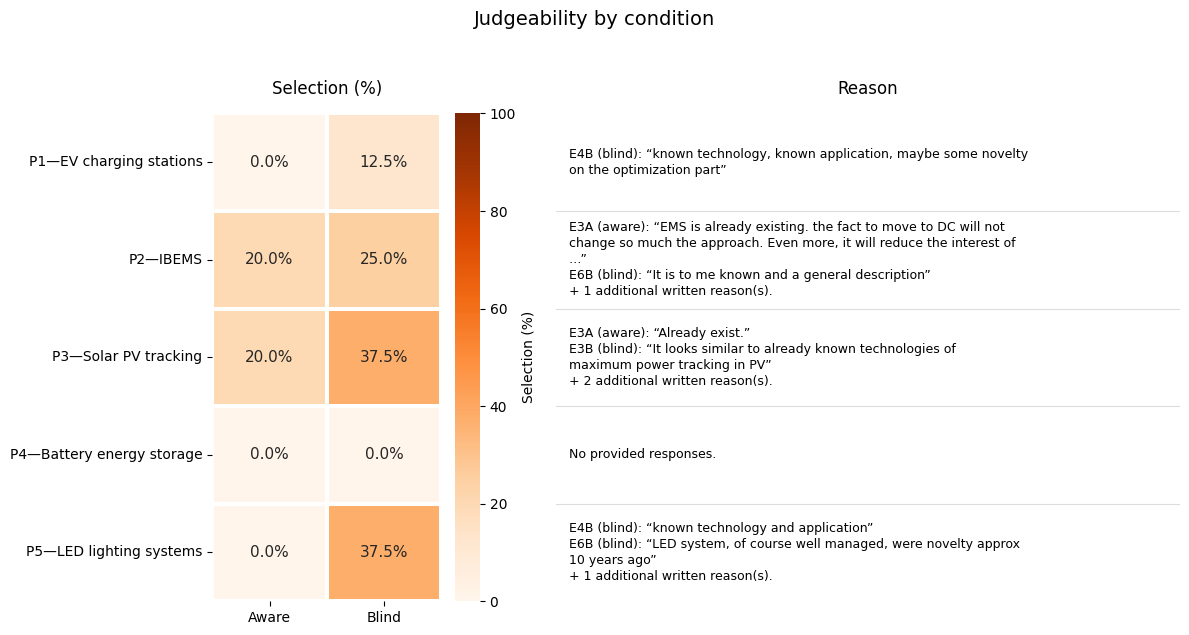

In [8]:
# Annotated judgeability heatmap with reason excerpts

proposal_ids = ["P1", "P2", "P3", "P4", "P5"]
conditions = ["aware", "blind"]

proposal_labels = {
    "P1": "P1—EV charging stations",
    "P2": "P2—IBEMS",
    "P3": "P3—Solar PV tracking",
    "P4": "P4—Battery energy storage",
    "P5": "P5—LED lighting systems",
}

MAX_EXCERPTS_PER_PROPOSAL = 2
MAX_EXCERPT_CHARACTERS = 130


# Use a copy of the existing expert–proposal data.
plot_data = judgeability_df[
    [
        "expert_code",
        "proposal_id",
        "condition",
        "ability_to_judge",
        "reason_unable_to_judge",
    ]
].copy()

if plot_data.duplicated(
    ["expert_code", "proposal_id"]
).any():
    raise ValueError("Duplicate expert–proposal records found.")

if not plot_data["ability_to_judge"].isin(["Yes", "No"]).all():
    raise ValueError("Judgeability must contain only Yes or No.")

if not plot_data["condition"].isin(conditions).all():
    raise ValueError("Unexpected condition labels found.")


# Count unable-to-judge responses and all responses.
counts = (
    plot_data
    .groupby(
        ["proposal_id", "condition"],
        observed=True,
    )
    .agg(
        total=("expert_code", "size"),
        unable=(
            "ability_to_judge",
            lambda values: values.eq("No").sum(),
        ),
    )
)

full_index = pd.MultiIndex.from_product(
    [proposal_ids, conditions],
    names=["proposal_id", "condition"],
)

counts = counts.reindex(full_index, fill_value=0)

counts["percentage"] = (
    100 * counts["unable"]
    / counts["total"].replace(0, np.nan)
)

percentages = (
    counts["percentage"]
    .unstack("condition")
    .reindex(index=proposal_ids, columns=conditions)
)

annotations = pd.DataFrame(
    "",
    index=proposal_ids,
    columns=conditions,
)

for proposal_id in proposal_ids:
    for condition in conditions:
        record = counts.loc[(proposal_id, condition)]

        if record["total"] > 0:
            annotations.loc[proposal_id, condition] = (
                f"{record['percentage']:.1f}%"
            )


# Prepare attributed excerpts from actual written reasons.
reason_text = {}

for proposal_id in proposal_ids:
    unable_records = plot_data.loc[
        plot_data["proposal_id"].eq(proposal_id)
        & plot_data["ability_to_judge"].eq("No")
    ].sort_values(["condition", "expert_code"])

    if unable_records.empty:
        reason_text[proposal_id] = (
            "No provided responses."
        )
        continue

    written = unable_records.loc[
        unable_records["reason_unable_to_judge"].notna()
        & unable_records["reason_unable_to_judge"]
            .astype("string")
            .str.strip()
            .ne("")
    ]

    excerpts = []

    for _, record in written.head(
        MAX_EXCERPTS_PER_PROPOSAL
    ).iterrows():
        excerpt = shorten(
            str(record["reason_unable_to_judge"]),
            width=MAX_EXCERPT_CHARACTERS,
            placeholder=" …",
        )

        excerpts.append(
            fill(
                f'{record["expert_code"]} '
                f'({record["condition"]}): “{excerpt}”',
                width=70,
            )
        )

    additional = len(written) - len(excerpts)
    missing_reasons = len(unable_records) - len(written)

    if additional > 0:
        excerpts.append(
            f"+ {additional} additional written reason(s)."
        )

    if missing_reasons > 0:
        excerpts.append(
            f"{missing_reasons} response(s) without "
            "a written reason."
        )

    reason_text[proposal_id] = "\n".join(excerpts)


# Draw heatmap and adjacent explanation panel.
fig, (heatmap_ax, reasons_ax) = plt.subplots(
    1,
    2,
    figsize=(12, 7),
    gridspec_kw={"width_ratios": [1.1, 2.4]},
)

sns.heatmap(
    percentages,
    annot=annotations,
    fmt="",
    mask=percentages.isna(),
    cmap="Oranges",
    vmin=0,
    vmax=100,
    linewidths=1.5,
    linecolor="white",
    annot_kws={"fontsize": 11},
    cbar_kws={"label": "Selection (%)"},
    ax=heatmap_ax,
)

heatmap_ax.set_xticklabels(
    ["Aware", "Blind"],
    rotation=0,
)

heatmap_ax.set_yticklabels(
    [proposal_labels[p] for p in proposal_ids],
    rotation=0,
)

heatmap_ax.set_xlabel("")
heatmap_ax.set_ylabel("")
heatmap_ax.set_title("Selection (%)", pad=14)


reasons_ax.set_xlim(0, 1)
reasons_ax.set_ylim(len(proposal_ids), 0)
reasons_ax.axis("off")
reasons_ax.set_title("Reason", pad=14)

for position, proposal_id in enumerate(proposal_ids):
    reasons_ax.text(
        0.02,
        position + 0.5,
        reason_text[proposal_id],
        ha="left",
        va="center",
        fontsize=9,
        linespacing=1.3,
    )

    if position > 0:
        reasons_ax.axhline(
            position,
            color="#DDDDDD",
            linewidth=0.8,
        )


fig.suptitle(
    "Judgeability by condition",
    fontsize=14,
    y=0.98,
)

# Add a footnote with additional information.

plt.tight_layout(rect=[0, 0.08, 1, 0.95])

FIGURE_DIR = BASE_DIR / "outputs" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

figure_name = "judgeability_heatmap_with_reasons"

for extension in ["eps", "pdf", "png"]:
    output_file = FIGURE_DIR / (
        f"{figure_name}.{extension}"
    )

    fig.savefig(
        output_file,
        format=extension,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    print(f"Figure exported to: {output_file}")

plt.show()

#### Proposal evaluation stage
- novelty, similarity, novelty drivers, previous exposure, and confidence

Figure exported to: /Users/HP/Documents/EICS-2026/expertsRatings/outputs/figures/proposal_nominal_responses.eps
Figure exported to: /Users/HP/Documents/EICS-2026/expertsRatings/outputs/figures/proposal_nominal_responses.png


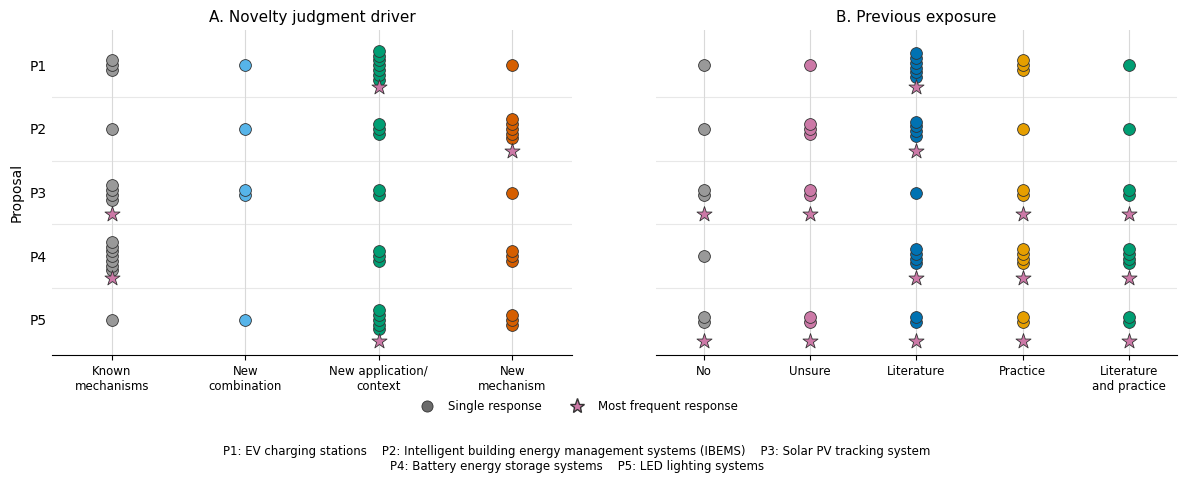

In [12]:
# Two-panel nominal-variable figure
# Panel A: Novelty judgment driver
# Panel B: Previous exposure
# 1. Define the five proposal blocks
nominal_blocks = [
    {
        "proposal_id": "P1",
        "proposal": "EV charging stations",
        "ability_column": (
            "Based on this description, can you judge the novelty "
            "of the EV charging stations?"
        ),
        "driver_column": (
            "Which aspect drive your novelty judgment?"
        ),
        "exposure_column": (
            "Have you previously seen or worked on a "
            "substantially similar DC solution?"
        ),
    },
    {
        "proposal_id": "P2",
        "proposal": (
            "Intelligent building energy management systems (IBEMS)"
        ),
        "ability_column": (
            "Based on this description, can you judge the novelty "
            "of the IBEMS?"
        ),
        "driver_column": (
            "Which aspect drive your novelty judgment for IBEMS?"
        ),
        "exposure_column": (
            "Have you previously seen or worked on a "
            "substantially similar DC solution?2"
        ),
    },
    {
        "proposal_id": "P3",
        "proposal": "Solar PV tracking system",
        "ability_column": (
            "Based on this description, can you judge the novelty "
            "of the solar PV tracking system?"
        ),
        "driver_column": (
            "Which aspect drive your novelty judgment for "
            "solar PV tracking system?"
        ),
        "exposure_column": (
            "Have you previously seen or worked on a "
            "substantially similar DC solution?3"
        ),
    },
    {
        "proposal_id": "P4",
        "proposal": "Battery energy storage systems",
        "ability_column": (
            "Based on this description, can you judge the novelty "
            "of the battery energy storage systems?"
        ),
        "driver_column": (
            "Which aspect drive your novelty judgment for "
            "battery energy storage systems?"
        ),
        "exposure_column": (
            "Have you previously seen or worked on a "
            "substantially similar DC solution?4"
        ),
    },
    {
        "proposal_id": "P5",
        "proposal": "LED lighting systems",
        "ability_column": (
            "Based on this description, can you judge the novelty "
            "of the LED lighting systems?"
        ),
        "driver_column": (
            "Which aspect drive your novelty judgment for "
            "LED lighting systems?"
        ),
        "exposure_column": (
            "Have you previously seen or worked on a "
            "substantially similar DC solution?5"
        ),
    },
]


# ------------------------------------------------------------
# 2. Define the nominal response categories
# ------------------------------------------------------------

driver_categories = [
    "Known mechanisms and combination",
    "New combination of known components",
    "New application/context for known technologies",
    "New mechanism/technical principle",
]

driver_axis_labels = [
    "Known\nmechanisms",
    "New\ncombination",
    "New application/\ncontext",
    "New\nmechanism",
]


exposure_categories = [
    "No",
    "Unsure",
    "Yes - in literature",
    "Yes - in practice",
    "Yes - both in practice and literature",
]

exposure_axis_labels = [
    "No",
    "Unsure",
    "Literature",
    "Practice",
    "Literature\nand practice",
]


# ------------------------------------------------------------
# 3. Create the eligible long-form dataset
# ------------------------------------------------------------

nominal_frames = []


for block in nominal_blocks:
    required_columns = [
        "expert_code",
        block["ability_column"],
        block["driver_column"],
        block["exposure_column"],
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in raw_df.columns
    ]

    if missing_columns:
        raise KeyError(
            f"Missing columns for {block['proposal_id']}: "
            f"{missing_columns}"
        )

    eligible = (
        raw_df[block["ability_column"]]
        .astype("string")
        .str.strip()
        .str.casefold()
        .eq("yes")
    )

    proposal_df = (
        raw_df.loc[
            eligible,
            [
                "expert_code",
                block["driver_column"],
                block["exposure_column"],
            ],
        ]
        .copy()
        .rename(
            columns={
                block["driver_column"]: "novelty_driver",
                block["exposure_column"]: "previous_exposure",
            }
        )
    )

    proposal_df["proposal_id"] = block["proposal_id"]
    proposal_df["proposal"] = block["proposal"]

    proposal_df["novelty_driver"] = (
        proposal_df["novelty_driver"]
        .astype("string")
        .str.strip()
    )

    proposal_df["previous_exposure"] = (
        proposal_df["previous_exposure"]
        .astype("string")
        .str.strip()
    )

    unexpected_drivers = set(
        proposal_df["novelty_driver"].dropna()
    ) - set(driver_categories)

    unexpected_exposure = set(
        proposal_df["previous_exposure"].dropna()
    ) - set(exposure_categories)

    if unexpected_drivers:
        raise ValueError(
            f"Unexpected driver categories for "
            f"{block['proposal_id']}: "
            f"{sorted(unexpected_drivers)}"
        )

    if unexpected_exposure:
        raise ValueError(
            f"Unexpected exposure categories for "
            f"{block['proposal_id']}: "
            f"{sorted(unexpected_exposure)}"
        )

    if proposal_df["novelty_driver"].isna().any():
        raise ValueError(
            f"A novelty-driver response is missing among "
            f"eligible experts for {block['proposal_id']}."
        )

    if proposal_df["previous_exposure"].isna().any():
        raise ValueError(
            f"A previous-exposure response is missing among "
            f"eligible experts for {block['proposal_id']}."
        )

    nominal_frames.append(proposal_df)


nominal_long_df = pd.concat(
    nominal_frames,
    ignore_index=True,
)


# ------------------------------------------------------------
# 4. Configure the two-panel figure
# ------------------------------------------------------------

proposal_ids = [
    block["proposal_id"]
    for block in nominal_blocks
]

# P1 appears at the top and P5 at the bottom.
base_positions = np.arange(
    len(proposal_ids) - 1,
    -1,
    -1,
)

vertical_spacing = 0.075


driver_colours = [
    "#999999",
    "#56B4E9",
    "#009E73",
    "#D55E00",
]

exposure_colours = [
    "#999999",
    "#CC79A7",
    "#0072B2",
    "#E69F00",
    "#009E73",
]


fig, axes = plt.subplots(
    1,
    2,
    figsize=(12.5, 5.5),
    sharey=True,
)

driver_ax = axes[0]
exposure_ax = axes[1]


# ------------------------------------------------------------
# 5. Panel A: Novelty judgment driver
# ------------------------------------------------------------

for block, base_y in zip(
    nominal_blocks,
    base_positions,
):
    proposal_data = nominal_long_df.loc[
        nominal_long_df["proposal_id"].eq(
            block["proposal_id"]
        )
    ]

    driver_counts = (
        proposal_data["novelty_driver"]
        .value_counts()
        .reindex(driver_categories, fill_value=0)
    )

    for category_position, count in enumerate(
        driver_counts.to_numpy()
    ):
        if count == 0:
            continue

        vertical_offsets = (
            np.arange(count)
            - (count - 1) / 2
        ) * vertical_spacing

        driver_ax.scatter(
            np.repeat(category_position, count),
            base_y + vertical_offsets,
            s=72,
            color=driver_colours[category_position],
            edgecolor="#333333",
            linewidth=0.6,
            zorder=3,
        )


driver_ax.set_xticks(
    np.arange(len(driver_axis_labels))
)

driver_ax.set_xticklabels(
    driver_axis_labels,
    fontsize=8.5,
)

driver_ax.set_yticks(base_positions)
driver_ax.set_yticklabels(proposal_ids)

driver_ax.set_xlim(-0.45, len(driver_categories) - 0.55)
driver_ax.set_ylim(-0.55, len(proposal_ids) - 0.45)

#driver_ax.set_xlabel("Selected novelty driver")
driver_ax.set_ylabel("Proposal")

driver_ax.set_title(
    "A. Novelty judgment driver",
    fontsize=11,
    #fontweight="bold",
)


# ------------------------------------------------------------
# 6. Panel B: Previous exposure
# ------------------------------------------------------------

for block, base_y in zip(
    nominal_blocks,
    base_positions,
):
    proposal_data = nominal_long_df.loc[
        nominal_long_df["proposal_id"].eq(
            block["proposal_id"]
        )
    ]

    exposure_counts = (
        proposal_data["previous_exposure"]
        .value_counts()
        .reindex(exposure_categories, fill_value=0)
    )

    for category_position, count in enumerate(
        exposure_counts.to_numpy()
    ):
        if count == 0:
            continue

        vertical_offsets = (
            np.arange(count)
            - (count - 1) / 2
        ) * vertical_spacing

        exposure_ax.scatter(
            np.repeat(category_position, count),
            base_y + vertical_offsets,
            s=72,
            color=exposure_colours[category_position],
            edgecolor="#333333",
            linewidth=0.6,
            zorder=3,
        )


exposure_ax.set_xticks(
    np.arange(len(exposure_axis_labels))
)

exposure_ax.set_xticklabels(
    exposure_axis_labels,
    fontsize=8.5,
)

exposure_ax.set_xlim(
    -0.45,
    len(exposure_categories) - 0.55,
)

#exposure_ax.set_xlabel("Previous exposure")
exposure_ax.set_ylabel("")

exposure_ax.tick_params(
    axis="y",
    labelleft=False,
    left=False,
)

exposure_ax.set_title(
    "B. Previous exposure",
    fontsize=11,
    #fontweight="bold",
)

# Highlight the most frequently selected category for each proposal.
for ax, response_column, categories in [
    (driver_ax, "novelty_driver", driver_categories),
    (exposure_ax, "previous_exposure", exposure_categories),
]:
    for proposal_id, base_y in zip(proposal_ids, base_positions):
        counts = (
            nominal_long_df.loc[
                nominal_long_df["proposal_id"].eq(proposal_id),
                response_column,
            ]
            .value_counts()
            .reindex(categories, fill_value=0)
        )

        if counts.sum() == 0:
            continue

        # Retain every category tied for the highest count.
        mode_positions = np.flatnonzero(
            counts.to_numpy() == counts.max()
        )

        ax.scatter(
            mode_positions,
            np.repeat(base_y - 0.34, len(mode_positions)),
            marker="*",
            s=130,
            color="#CC79A7",
            edgecolor="#333333",
            linewidth=0.6,
            zorder=5,
        )

# 7. Apply common formatting
for ax in axes:
    ax.grid(
        axis="x",
        color="#D9D9D9",
        linewidth=0.8,
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)

    ax.tick_params(
        axis="y",
        length=0,
    )

    # Light separators between proposal rows.
    for separator in np.arange(
        0.5,
        len(proposal_ids) - 0.5,
        1,
    ):
        ax.axhline(
            separator,
            color="#E8E8E8",
            linewidth=0.8,
            zorder=0,
        )


#fig.suptitle("Factors supporting experts' novelty judgments", fontsize=13, fontweight="bold", y=0.97, )

# 8. Shared proposal-name key
proposal_key = (
    "P1: EV charging stations    "
    "P2: Intelligent building energy management systems (IBEMS)    "
    "P3: Solar PV tracking system\n"
    "P4: Battery energy storage systems    "
    "P5: LED lighting systems"
)

fig.text(
    0.5,
    0.035,
    proposal_key,
    ha="center",
    va="bottom",
    fontsize=8.5,
)


# Shared dot explanation for both panels.
expert_dot_handle = Line2D(
    [0],
    [0],
    marker="o",
    linestyle="None",
    markerfacecolor="#6B6B6B",
    markeredgecolor="#333333",
    markeredgewidth=0.6,
    markersize=8,
    label="Single response",
)
mode_handle = Line2D(
    [0], [0],
    marker="*",
    linestyle="None",
    markerfacecolor="#CC79A7",
    markeredgecolor="#333333",
    markersize=11,
    label="Most frequent response",
)
fig.legend(
    handles=[expert_dot_handle, mode_handle],
    loc="lower center",
    bbox_to_anchor=(0.5, 0.125),
    frameon=False,
    fontsize=8.5,
    ncol=2,
)


fig.subplots_adjust(
    left=0.08,
    right=0.98,
    top=0.84,
    bottom=0.25,
    wspace=0.16,
)
# Save the nominal figure as EPS and PNG.
FIGURE_DIR = BASE_DIR / "outputs" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

figure_name = "proposal_nominal_responses"

for extension in ["eps", "png"]:
    output_file = FIGURE_DIR / f"{figure_name}.{extension}"

    fig.savefig(
        output_file,
        format=extension,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    print(f"Figure exported to: {output_file}")
plt.show()

Figure exported to: /Users/HP/Documents/EICS-2026/expertsRatings/outputs/figures/proposal_ordinal_ratings.eps
Figure exported to: /Users/HP/Documents/EICS-2026/expertsRatings/outputs/figures/proposal_ordinal_ratings.png


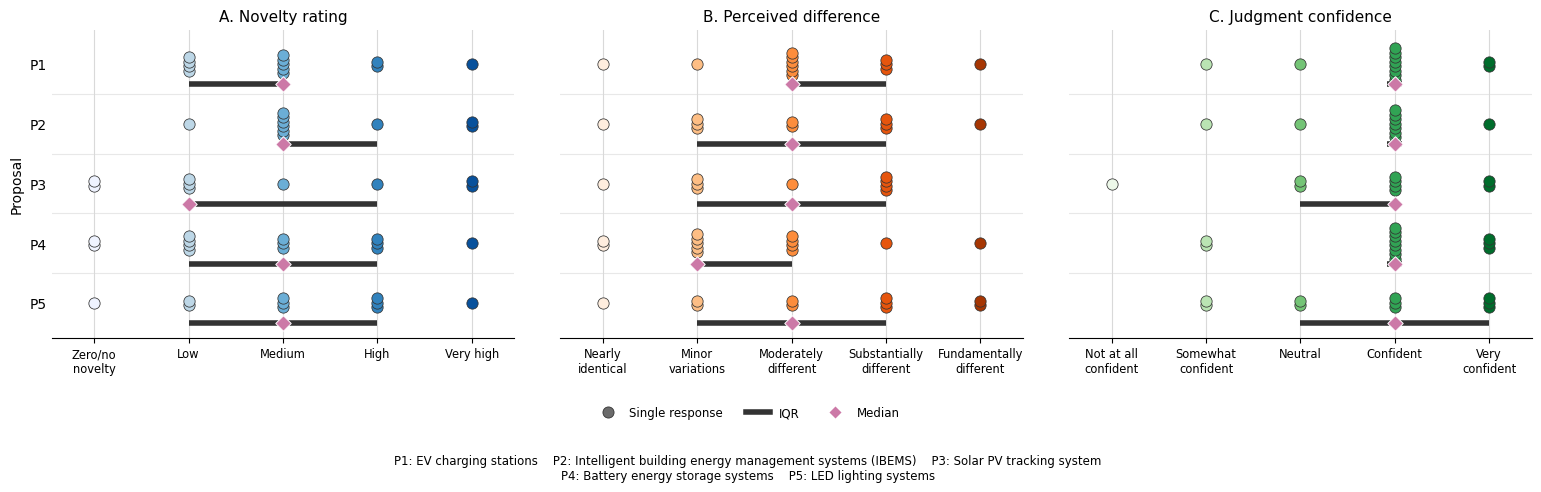

In [15]:
# Three-panel ordinal-variable figure
# Panel A: Novelty rating
# Panel B: Perceived difference from existing solutions
# Panel C: Confidence in the novelty judgment
# Define the proposal question blocks
ordinal_blocks = [
    {
        "proposal_id": "P1",
        "proposal": "EV charging stations",
        "ability_column": (
            "Based on this description, can you judge the novelty "
            "of the EV charging stations?"
        ),
        "novelty_column": "Novelty",
        "difference_column": "Similarity",
        "confidence_column": "Confidence interval",
    },
    {
        "proposal_id": "P2",
        "proposal": (
            "Intelligent building energy management systems (IBEMS)"
        ),
        "ability_column": (
            "Based on this description, can you judge the novelty "
            "of the IBEMS?"
        ),
        "novelty_column": "Novelty2",
        "difference_column": "Similarity2",
        "confidence_column": "Confidence interval2",
    },
    {
        "proposal_id": "P3",
        "proposal": "Solar PV tracking system",
        "ability_column": (
            "Based on this description, can you judge the novelty "
            "of the solar PV tracking system?"
        ),
        "novelty_column": "Novelty3",
        "difference_column": "Similarity3",
        "confidence_column": "Confidence interval3",
    },
    {
        "proposal_id": "P4",
        "proposal": "Battery energy storage systems",
        "ability_column": (
            "Based on this description, can you judge the novelty "
            "of the battery energy storage systems?"
        ),
        "novelty_column": "Novelty4",
        "difference_column": "Similarity4",
        "confidence_column": "Confidence interval4",
    },
    {
        "proposal_id": "P5",
        "proposal": "LED lighting systems",
        "ability_column": (
            "Based on this description, can you judge the novelty "
            "of the LED lighting systems?"
        ),
        "novelty_column": "Novelty5",
        "difference_column": "Similarity5",
        "confidence_column": "Confidence interval5",
    },
]


# 2. Define the ordered response scales
novelty_categories = [
    "Zero/no novelty",
    "Low novelty",
    "Medium novelty",
    "High novelty",
    "Very high novelty",
]

difference_categories = [
    "Nearly identical",
    "Minor variations",
    "Moderately different",
    "Substantially different",
    "Fundamentally different",
]

confidence_categories = [
    "Not at all confident",
    "Somewhat confident",
    "Neutral",
    "Confident",
    "Very confident",
]


novelty_score_map = {
    label: score
    for score, label in enumerate(
        novelty_categories
    )
}

difference_score_map = {
    label: score
    for score, label in enumerate(
        difference_categories
    )
}

confidence_score_map = {
    label: score
    for score, label in enumerate(
        confidence_categories
    )
}


# Short axis labels.
novelty_axis_labels = [
    "Zero/no\nnovelty",
    "Low",
    "Medium",
    "High",
    "Very high",
]

difference_axis_labels = [
    "Nearly\nidentical",
    "Minor\nvariations",
    "Moderately\ndifferent",
    "Substantially\ndifferent",
    "Fundamentally\ndifferent",
]

confidence_axis_labels = [
    "Not at all\nconfident",
    "Somewhat\nconfident",
    "Neutral",
    "Confident",
    "Very\nconfident",
]

# 3. Create the eligible long-form dataset
ordinal_frames = []


for block in ordinal_blocks:
    required_columns = [
        "expert_code",
        block["ability_column"],
        block["novelty_column"],
        block["difference_column"],
        block["confidence_column"],
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in raw_df.columns
    ]

    if missing_columns:
        raise KeyError(
            f"Missing columns for {block['proposal_id']}: "
            f"{missing_columns}"
        )

    eligible = (
        raw_df[block["ability_column"]]
        .astype("string")
        .str.strip()
        .str.casefold()
        .eq("yes")
    )

    proposal_df = (
        raw_df.loc[
            eligible,
            [
                "expert_code",
                block["novelty_column"],
                block["difference_column"],
                block["confidence_column"],
            ],
        ]
        .copy()
        .rename(
            columns={
                block["novelty_column"]: "novelty_label",
                block["difference_column"]: "difference_label",
                block["confidence_column"]: "confidence_label",
            }
        )
    )

    proposal_df["proposal_id"] = block["proposal_id"]
    proposal_df["proposal"] = block["proposal"]

    for column in [
        "novelty_label",
        "difference_label",
        "confidence_label",
    ]:
        proposal_df[column] = (
            proposal_df[column]
            .astype("string")
            .str.strip()
        )

    # Validate category values.
    unexpected_novelty = set(
        proposal_df["novelty_label"].dropna()
    ) - set(novelty_categories)

    unexpected_difference = set(
        proposal_df["difference_label"].dropna()
    ) - set(difference_categories)

    unexpected_confidence = set(
        proposal_df["confidence_label"].dropna()
    ) - set(confidence_categories)

    if unexpected_novelty:
        raise ValueError(
            f"Unexpected novelty categories for "
            f"{block['proposal_id']}: "
            f"{sorted(unexpected_novelty)}"
        )

    if unexpected_difference:
        raise ValueError(
            f"Unexpected difference categories for "
            f"{block['proposal_id']}: "
            f"{sorted(unexpected_difference)}"
        )

    if unexpected_confidence:
        raise ValueError(
            f"Unexpected confidence categories for "
            f"{block['proposal_id']}: "
            f"{sorted(unexpected_confidence)}"
        )

    # Eligible experts should have all three ratings.
    rating_columns = [
        "novelty_label",
        "difference_label",
        "confidence_label",
    ]

    if proposal_df[rating_columns].isna().any().any():
        missing_rows = proposal_df.loc[
            proposal_df[rating_columns]
            .isna()
            .any(axis=1),
            ["expert_code"] + rating_columns,
        ]

        raise ValueError(
            f"Missing ordinal responses among eligible experts "
            f"for {block['proposal_id']}:\n{missing_rows}"
        )

    proposal_df["novelty_score"] = (
        proposal_df["novelty_label"]
        .map(novelty_score_map)
        .astype(int)
    )

    proposal_df["difference_score"] = (
        proposal_df["difference_label"]
        .map(difference_score_map)
        .astype(int)
    )

    proposal_df["confidence_score"] = (
        proposal_df["confidence_label"]
        .map(confidence_score_map)
        .astype(int)
    )

    ordinal_frames.append(proposal_df)


ordinal_long_df = pd.concat(
    ordinal_frames,
    ignore_index=True,
)

# 4. Configure the figure
proposal_ids = [
    block["proposal_id"]
    for block in ordinal_blocks
]

# P1 appears at the top.
base_positions = np.arange(
    len(proposal_ids) - 1,
    -1,
    -1,
)

vertical_spacing = 0.075


novelty_colours = [
    "#EFF3FF",
    "#BDD7E7",
    "#6BAED6",
    "#3182BD",
    "#08519C",
]

difference_colours = [
    "#FEEDDE",
    "#FDBE85",
    "#FD8D3C",
    "#E6550D",
    "#A63603",
]

confidence_colours = [
    "#EDF8E9",
    "#BAE4B3",
    "#74C476",
    "#31A354",
    "#006D2C",
]


# Colour used for the median diamond in all three panels.
median_colour = "#CC79A7"

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5.6),
    sharey=True,
)

# 5. Reusable ordinal-panel function
def draw_ordinal_panel(
    ax,
    score_column,
    axis_labels,
    category_colours,
    panel_title,
):
    """Draw individual ratings, median and IQR by proposal."""

    for block, base_y in zip(
        ordinal_blocks,
        base_positions,
    ):
        proposal_scores = ordinal_long_df.loc[
            ordinal_long_df["proposal_id"].eq(
                block["proposal_id"]
            ),
            score_column,
        ]

        score_counts = (
            proposal_scores
            .value_counts()
            .reindex(range(5), fill_value=0)
        )

        # One dot for each eligible expert rating.
        for score, count in score_counts.items():
            if count == 0:
                continue

            vertical_offsets = (
                np.arange(count)
                - (count - 1) / 2
            ) * vertical_spacing

            ax.scatter(
                np.repeat(score, count),
                base_y + vertical_offsets,
                s=66,
                color=category_colours[score],
                edgecolor="#333333",
                linewidth=0.55,
                zorder=3,
            )

        # Category-based median and IQR.
        q1_score = int(
            proposal_scores.quantile(
                0.25,
                interpolation="nearest",
            )
        )

        median_score = int(
            proposal_scores.quantile(
                0.50,
                interpolation="nearest",
            )
        )

        q3_score = int(
            proposal_scores.quantile(
                0.75,
                interpolation="nearest",
            )
        )

        summary_y = base_y - 0.34

        # Ensure an IQR marker remains visible when Q1 equals Q3.
        if q1_score == q3_score:
            iqr_start = q1_score - 0.08
            iqr_end = q3_score + 0.08
        else:
            iqr_start = q1_score
            iqr_end = q3_score

        ax.hlines(
            y=summary_y,
            xmin=iqr_start,
            xmax=iqr_end,
            color="#333333",
            linewidth=4,
            zorder=2,
        )

        ax.scatter(
            median_score,
            summary_y,
            marker="D",
            s=62,
            color=median_colour,
            edgecolor="white",
            linewidth=0.7,
            zorder=4,
        )

    ax.set_xticks(np.arange(5))
    ax.set_xticklabels(
        axis_labels,
        fontsize=8.3,
    )

    ax.set_xlim(-0.45, 4.45)
    ax.set_ylim(
        -0.58,
        len(proposal_ids) - 0.42,
    )

    ax.set_title(
        panel_title,
        fontsize=11,
        #fontweight="bold",
    )

    ax.grid(
        axis="x",
        color="#D9D9D9",
        linewidth=0.8,
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)

    ax.tick_params(
        axis="y",
        length=0,
    )

    # Light separators between proposal rows.
    for separator in np.arange(
        0.5,
        len(proposal_ids) - 0.5,
        1,
    ):
        ax.axhline(
            separator,
            color="#E8E8E8",
            linewidth=0.8,
            zorder=0,
        )

# 6. Draw the three panels
draw_ordinal_panel(
    ax=axes[0],
    score_column="novelty_score",
    axis_labels=novelty_axis_labels,
    category_colours=novelty_colours,
    panel_title="A. Novelty rating",
)

draw_ordinal_panel(
    ax=axes[1],
    score_column="difference_score",
    axis_labels=difference_axis_labels,
    category_colours=difference_colours,
    panel_title="B. Perceived difference",
)

draw_ordinal_panel(
    ax=axes[2],
    score_column="confidence_score",
    axis_labels=confidence_axis_labels,
    category_colours=confidence_colours,
    panel_title="C. Judgment confidence",
)


# Show P1–P5 only on the leftmost panel.
axes[0].set_yticks(base_positions)
axes[0].set_yticklabels(proposal_ids)
axes[0].set_ylabel("Proposal")

for ax in axes[1:]:
    ax.tick_params(
        axis="y",
        labelleft=False,
        left=False,
    )

    ax.set_ylabel("")

# 7. Shared title, legend and proposal key
#fig.suptitle("Expert ratings across the five proposals", fontsize=13, fontweight="bold", y=0.97)
shared_legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markerfacecolor="#6B6B6B",
        markeredgecolor="#333333",
        markeredgewidth=0.6,
        markersize=8,
        label="Single response",
    ),
    Line2D(
        [0],
        [0],
        color="#333333",
        linewidth=4,
        label="IQR",
    ),
    Line2D(
        [0],
        [0],
        marker="D",
        linestyle="None",
        markerfacecolor=median_colour,
        markeredgecolor="white",
        markersize=7,
        label="Median",
    ),
]


fig.legend(
    handles=shared_legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.125),
    frameon=False,
    fontsize=8.5,
    ncol=3,
)


proposal_key = (
    "P1: EV charging stations    "
    "P2: Intelligent building energy management systems (IBEMS)    "
    "P3: Solar PV tracking system\n"
    "P4: Battery energy storage systems    "
    "P5: LED lighting systems"
)


fig.text(
    0.5,
    0.032,
    proposal_key,
    ha="center",
    va="bottom",
    fontsize=8.5,
)


fig.subplots_adjust(
    left=0.065,
    right=0.99,
    top=0.84,
    bottom=0.29,
    wspace=0.10,
)
# Save the ordinal figure as EPS, PDF, and PNG.
FIGURE_DIR = BASE_DIR / "outputs" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

figure_name = "proposal_ordinal_ratings"

for extension in ["eps", "png"]:
    output_file = FIGURE_DIR / f"{figure_name}.{extension}"

    fig.savefig(
        output_file,
        format=extension,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    print(f"Figure exported to: {output_file}")
plt.show()

### Kendall Tau, bootstrap confidence intervals, permutations, Holm computations
- Cells are in this flow:
    - Paired novelty–difference data preparation
    - Kendall’s \(\tau_b\) calculation
    - Bootstrap confidence intervals calculation
    - Permutation \(p\)-values calculation
    - Holm correction application
    - Presentation and export of the final results table in Latex format

In [16]:
# Paired novelty–difference data preparation
required_columns = [
    "expert_code",
    "proposal_id",
    "proposal",
    "novelty_score",
    "difference_score",
]

missing_columns = [
    column
    for column in required_columns
    if column not in ordinal_long_df.columns
]

if missing_columns:
    raise KeyError(
        "The following columns are missing from"
        f"ordinal_long_df: {missing_columns}"
    )


# Retain the novelty and perceived-difference pairs.
kendall_pairs_df = (
    ordinal_long_df[required_columns]
    .copy()
)


# Confirm one record per expert and proposal.
duplicate_pairs = kendall_pairs_df.duplicated(
    subset=["expert_code", "proposal_id"]
)

if duplicate_pairs.any():
    raise ValueError(
        "Duplicate expert–proposal rating pairs were detected:\n"
        f"{kendall_pairs_df.loc[duplicate_pairs]}"
    )


# Identify records missing either member of the pair.
kendall_pairs_df["complete_pair"] = (
    kendall_pairs_df[
        ["novelty_score", "difference_score"]
    ]
    .notna()
    .all(axis=1)
)


pair_completeness = (
    kendall_pairs_df
    .groupby(
        ["proposal_id", "proposal"],
        observed=True,
        sort=False,
    )
    .agg(
        eligible_records=("expert_code", "size"),
        complete_pairs=("complete_pair", "sum"),
    )
    .reset_index()
)

pair_completeness["incomplete_pairs"] = (
    pair_completeness["eligible_records"]
    - pair_completeness["complete_pairs"]
)


# Retain only complete pairs for Kendall's tau.
kendall_pairs_df = (
    kendall_pairs_df.loc[
        kendall_pairs_df["complete_pair"],
        [
            "expert_code",
            "proposal_id",
            "proposal",
            "novelty_score",
            "difference_score",
        ],
    ]
    .reset_index(drop=True)
)


# Ensure the scores are numeric.
kendall_pairs_df["novelty_score"] = (
    pd.to_numeric(
        kendall_pairs_df["novelty_score"],
        errors="raise",
    )
)

kendall_pairs_df["difference_score"] = (
    pd.to_numeric(
        kendall_pairs_df["difference_score"],
        errors="raise",
    )
)


proposal_order = ["P1", "P2", "P3", "P4", "P5"]

kendall_pairs_df["proposal_id"] = pd.Categorical(
    kendall_pairs_df["proposal_id"],
    categories=proposal_order,
    ordered=True,
)

kendall_pairs_df = (
    kendall_pairs_df
    .sort_values(["proposal_id", "expert_code"])
    .reset_index(drop=True)
)


print(
    f"Complete novelty–difference pairs: "
    f"{len(kendall_pairs_df)}"
)

display(pair_completeness)
display(kendall_pairs_df)

Complete novelty–difference pairs: 54


,proposal_id,proposal,eligible_records,complete_pairs,incomplete_pairs
0,P1,EV charging stations,12,12,0
1,P2,Intelligent building energy management systems...,10,10,0
2,P3,Solar PV tracking system,9,9,0
3,P4,Battery energy storage systems,13,13,0
4,P5,LED lighting systems,10,10,0


,expert_code,proposal_id,proposal,novelty_score,difference_score
0,E1A,P1,EV charging stations,1,0
1,E1B,P1,EV charging stations,2,2
2,E2A,P1,EV charging stations,4,4
3,E2B,P1,EV charging stations,2,2
4,E3A,P1,EV charging stations,2,3
5,E3B,P1,EV charging stations,3,2
6,E4A,P1,EV charging stations,2,2
7,E5A,P1,EV charging stations,2,1
8,E5B,P1,EV charging stations,3,3
9,E6B,P1,EV charging stations,1,2


In [18]:
#  Kendall’s \(\tau_b\) calculation
kendall_results = []
for proposal_id in proposal_order:
    proposal_data = kendall_pairs_df.loc[
        kendall_pairs_df["proposal_id"].eq(proposal_id)
    ]

    novelty = (
        proposal_data["novelty_score"]
        .to_numpy()
    )

    difference = (
        proposal_data["difference_score"]
        .to_numpy()
    )

    if len(proposal_data) < 3:
        raise ValueError(
            f"{proposal_id} has fewer than three paired ratings."
        )

    if len(np.unique(novelty)) < 2:
        raise ValueError(
            f"{proposal_id} has no variation in novelty ratings."
        )

    if len(np.unique(difference)) < 2:
        raise ValueError(
            f"{proposal_id} has no variation in "
            "perceived-difference ratings."
        )

    tau_result = kendalltau(
        novelty,
        difference,
        variant="b",
        method="auto",
    )

    if np.isnan(tau_result.statistic):
        raise ValueError(
            f"Kendall's tau-b could not be calculated "
            f"for {proposal_id}."
        )

    kendall_results.append(
        {
            "proposal_id": proposal_id,
            "proposal": str(
                proposal_data["proposal"].iloc[0]
            ),
            "paired_n": len(proposal_data),
            "kendall_tau_b": tau_result.statistic,
        }
    )


kendall_results_df = pd.DataFrame(
    kendall_results
)


display(
    kendall_results_df.style.format(
        {
            "kendall_tau_b": "{:.3f}",
        }
    )
)

,proposal_id,proposal,paired_n,kendall_tau_b
0,P1,EV charging stations,12,0.392
1,P2,Intelligent building energy management systems (IBEMS),10,0.783
2,P3,Solar PV tracking system,9,0.657
3,P4,Battery energy storage systems,13,0.715
4,P5,LED lighting systems,10,0.623


In [19]:
# Bootstrap confidence intervals calculation
KENDALL_BOOTSTRAP_REPETITIONS = 10_000
KENDALL_BOOTSTRAP_SEED = 20261002
KENDALL_CONFIDENCE_LEVEL = 0.95

kendall_bootstrap_rng = np.random.default_rng(
    KENDALL_BOOTSTRAP_SEED
)


def bootstrap_kendall_tau_b(
    novelty,
    difference,
    repetitions,
    rng,
):
    """
    Resample paired expert ratings and recalculate tau-b.

    Returns the percentile confidence interval and the number
    of valid bootstrap estimates.
    """
    novelty = np.asarray(novelty)
    difference = np.asarray(difference)

    number_of_pairs = len(novelty)
    bootstrap_estimates = []

    for _ in range(repetitions):
        sampled_indices = rng.integers(
            low=0,
            high=number_of_pairs,
            size=number_of_pairs,
        )

        sampled_novelty = novelty[sampled_indices]
        sampled_difference = difference[sampled_indices]

        estimate = kendalltau(
            sampled_novelty,
            sampled_difference,
            variant="b",
            method="auto",
        ).statistic

        # Some bootstrap samples may contain no variation.
        if not np.isnan(estimate):
            bootstrap_estimates.append(estimate)

    bootstrap_estimates = np.asarray(
        bootstrap_estimates
    )

    if len(bootstrap_estimates) == 0:
        raise ValueError(
            "No valid bootstrap estimates were obtained."
        )

    lower_probability = (
        1 - KENDALL_CONFIDENCE_LEVEL
    ) / 2

    upper_probability = 1 - lower_probability

    confidence_interval = np.quantile(
        bootstrap_estimates,
        [
            lower_probability,
            upper_probability,
        ],
    )

    return (
        confidence_interval[0],
        confidence_interval[1],
        len(bootstrap_estimates),
    )


bootstrap_results = []


for proposal_id in proposal_order:
    proposal_data = kendall_pairs_df.loc[
        kendall_pairs_df["proposal_id"].eq(proposal_id)
    ]

    ci_low, ci_high, valid_repetitions = (
        bootstrap_kendall_tau_b(
            novelty=(
                proposal_data["novelty_score"]
                .to_numpy()
            ),
            difference=(
                proposal_data["difference_score"]
                .to_numpy()
            ),
            repetitions=KENDALL_BOOTSTRAP_REPETITIONS,
            rng=kendall_bootstrap_rng,
        )
    )

    bootstrap_results.append(
        {
            "proposal_id": proposal_id,
            "bootstrap_ci_low": ci_low,
            "bootstrap_ci_high": ci_high,
            "valid_bootstrap_repetitions": (
                valid_repetitions
            ),
        }
    )


bootstrap_results_df = pd.DataFrame(
    bootstrap_results
)


display(
    bootstrap_results_df.style.format(
        {
            "bootstrap_ci_low": "{:.3f}",
            "bootstrap_ci_high": "{:.3f}",
        }
    )
)

,proposal_id,bootstrap_ci_low,bootstrap_ci_high,valid_bootstrap_repetitions
0,P1,-0.237,0.825,9996
1,P2,0.507,0.952,9945
2,P3,0.182,0.921,9991
3,P4,0.267,0.959,10000
4,P5,0.059,0.952,10000


In [20]:
# Permutation \(p\)-values calculation
PERMUTATION_REPETITIONS = 20_000
PERMUTATION_SEED = 20261003

permutation_rng = np.random.default_rng(
    PERMUTATION_SEED
)


def permutation_p_value_tau_b(
    novelty,
    difference,
    observed_tau,
    repetitions,
    rng,
):
    """
    Permute perceived-difference ratings across experts and
    recalculate Kendall's tau-b.

    Uses a two-sided test and the plus-one correction.
    """
    novelty = np.asarray(novelty)
    difference = np.asarray(difference)

    extreme_count = 0
    valid_permutations = 0

    observed_absolute_tau = abs(observed_tau)

    for _ in range(repetitions):
        permuted_difference = rng.permutation(
            difference
        )

        permuted_tau = kendalltau(
            novelty,
            permuted_difference,
            variant="b",
            method="auto",
        ).statistic

        if np.isnan(permuted_tau):
            continue

        valid_permutations += 1

        if (
            abs(permuted_tau)
            >= observed_absolute_tau - 1e-12
        ):
            extreme_count += 1

    if valid_permutations == 0:
        raise ValueError(
            "No valid permutation estimates were obtained."
        )

    p_value = (
        extreme_count + 1
    ) / (
        valid_permutations + 1
    )

    return p_value, valid_permutations


permutation_results = []


for proposal_id in proposal_order:
    proposal_data = kendall_pairs_df.loc[
        kendall_pairs_df["proposal_id"].eq(proposal_id)
    ]

    observed_tau = (
        kendall_results_df.loc[
            kendall_results_df["proposal_id"].eq(
                proposal_id
            ),
            "kendall_tau_b",
        ]
        .iloc[0]
    )

    permutation_p, valid_permutations = (
        permutation_p_value_tau_b(
            novelty=(
                proposal_data["novelty_score"]
                .to_numpy()
            ),
            difference=(
                proposal_data["difference_score"]
                .to_numpy()
            ),
            observed_tau=observed_tau,
            repetitions=PERMUTATION_REPETITIONS,
            rng=permutation_rng,
        )
    )

    permutation_results.append(
        {
            "proposal_id": proposal_id,
            "permutation_p": permutation_p,
            "valid_permutations": (
                valid_permutations
            ),
        }
    )


permutation_results_df = pd.DataFrame(
    permutation_results
)


display(
    permutation_results_df.style.format(
        {
            "permutation_p": "{:.4f}",
        }
    )
)

,proposal_id,permutation_p,valid_permutations
0,P1,0.1481,20000
1,P2,0.0042,20000
2,P3,0.0338,20000
3,P4,0.0015,20000
4,P5,0.0212,20000


In [21]:
# Holm correction application
def holm_adjust_p_values(p_values):
    """Return Holm-adjusted p-values."""
    p_values = np.asarray(
        p_values,
        dtype=float,
    )

    number_of_tests = len(p_values)
    sorted_indices = np.argsort(p_values)
    sorted_p_values = p_values[sorted_indices]

    adjusted_sorted = np.empty(
        number_of_tests,
        dtype=float,
    )

    running_maximum = 0.0

    for rank, p_value in enumerate(
        sorted_p_values
    ):
        adjustment_factor = (
            number_of_tests - rank
        )

        adjusted_value = (
            adjustment_factor * p_value
        )

        running_maximum = max(
            running_maximum,
            adjusted_value,
        )

        adjusted_sorted[rank] = min(
            running_maximum,
            1.0,
        )

    adjusted_p_values = np.empty(
        number_of_tests,
        dtype=float,
    )

    adjusted_p_values[
        sorted_indices
    ] = adjusted_sorted

    return adjusted_p_values


holm_results_df = permutation_results_df.copy()

holm_results_df["holm_adjusted_p"] = (
    holm_adjust_p_values(
        holm_results_df["permutation_p"]
    )
)

holm_results_df["holm_reject_0_05"] = (
    holm_results_df["holm_adjusted_p"] < 0.05
)


display(
    holm_results_df.style.format(
        {
            "permutation_p": "{:.4f}",
            "holm_adjusted_p": "{:.4f}",
        }
    )
)

,proposal_id,permutation_p,valid_permutations,holm_adjusted_p,holm_reject_0_05
0,P1,0.1481,20000,0.1481,False
1,P2,0.0042,20000,0.0168,True
2,P3,0.0338,20000,0.0676,False
3,P4,0.0015,20000,0.0077,True
4,P5,0.0212,20000,0.0636,False


In [41]:
# Presentation and export of the final results table in Latex format
final_kendall_results_df = (
    kendall_results_df
    .merge(
        bootstrap_results_df[
            [
                "proposal_id",
                "bootstrap_ci_low",
                "bootstrap_ci_high",
                "valid_bootstrap_repetitions",
            ]
        ],
        on="proposal_id",
        how="left",
        validate="one_to_one",
    )
    .merge(
        holm_results_df[
            [
                "proposal_id",
                "permutation_p",
                "holm_adjusted_p",
                "holm_reject_0_05",
                "valid_permutations",
            ]
        ],
        on="proposal_id",
        how="left",
        validate="one_to_one",
    )
)


final_kendall_results_df["proposal_id"] = (
    pd.Categorical(
        final_kendall_results_df["proposal_id"],
        categories=proposal_order,
        ordered=True,
    )
)

final_kendall_results_df = (
    final_kendall_results_df
    .sort_values("proposal_id")
    .reset_index(drop=True)
)


def format_p_value(value):
    if value < 0.001:
        return "<0.001"

    return f"{value:.3f}"


kendall_results_table = pd.DataFrame(
    {
        "Proposal": (
            final_kendall_results_df[
                "proposal_id"
            ].astype("string")
        ),
        "Paired n": (
            final_kendall_results_df[
                "paired_n"
            ].astype(int)
        ),
        "Kendall tau-b": (
            final_kendall_results_df[
                "kendall_tau_b"
            ].map(lambda value: f"{value:.3f}")
        ),
        "95% bootstrap CI": (
            final_kendall_results_df.apply(
                lambda row: (
                    f"[{row['bootstrap_ci_low']:.3f}, "
                    f"{row['bootstrap_ci_high']:.3f}]"
                ),
                axis=1,
            )
        ),
        "pHolm": (
            final_kendall_results_df[
                "holm_adjusted_p"
            ].map(format_p_value)
        ),
    }
)


display(kendall_results_table)


# Create a LaTeX-formatted copy: ommited the permutation p-values
kendall_latex_table = (
    kendall_results_table.rename(
        columns={
            "Paired n": r"Paired $n$",
            "Kendall tau-b": r"Kendall's $\tau_b$",
            "95% bootstrap CI": r"95\% bootstrap CI",
            "pHolm": r"Holm-adjusted $p$",
        }
    )
)


TABLE_DIR = BASE_DIR / "outputs" / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)

latex_file = (
    TABLE_DIR
    / "kendall_tau_novelty_difference.tex"
)


kendall_latex_table.to_latex(
    buf=latex_file,
    index=False,
    escape=False,
    caption=(
        "Proposal-specific associations between novelty "
        "ratings and perceived difference from existing "
        "solutions."
    ),
    label="tab:kendall_novelty_difference",
    position="htbp",
    column_format="lccccc",
)


print(f"LaTeX table exported to: {latex_file}")

,Proposal,Paired n,Kendall tau-b,95% bootstrap CI,pHolm
0,P1,12,0.392,"[-0.237, 0.825]",0.148
1,P2,10,0.783,"[0.507, 0.952]",0.017
2,P3,9,0.657,"[0.182, 0.921]",0.068
3,P4,13,0.715,"[0.267, 0.959]",0.008
4,P5,10,0.623,"[0.059, 0.952]",0.064


LaTeX table exported to: /Users/HP/Documents/EICS-2026/expertsRatings/outputs/tables/kendall_tau_novelty_difference.tex


#### Comparisons of effect between the groups (i.e., aware vs. blind)

In [26]:
# Data preparation and descriptive audit
proposal_order = ["P1", "P2", "P3", "P4", "P5"]

outcome_columns = {
    "Novelty": "novelty_score",
    "Perceived difference": "difference_score",
    "Confidence": "confidence_score",
}

outcome_order = list(outcome_columns.keys())


required_ordinal_columns = [
    "expert_code",
    "proposal_id",
    "proposal",
    *outcome_columns.values(),
]

missing_ordinal_columns = [
    column
    for column in required_ordinal_columns
    if column not in ordinal_long_df.columns
]

if missing_ordinal_columns:
    raise KeyError(
        "The following columns are missing from "
        f"ordinal_long_df: {missing_ordinal_columns}"
    )


required_group_columns = [
    "expert_code",
    "condition",
    "condition_label",
]

missing_group_columns = [
    column
    for column in required_group_columns
    if column not in raw_df.columns
]

if missing_group_columns:
    raise KeyError(
        "The following columns are missing from "
        f"raw_df: {missing_group_columns}"
    )


# Create one condition record per expert.
expert_groups_df = (
    raw_df[required_group_columns]
    .drop_duplicates()
    .reset_index(drop=True)
)


# Each expert must belong to one condition only.
duplicate_group_records = expert_groups_df.duplicated(
    subset=["expert_code"],
    keep=False,
)

if duplicate_group_records.any():
    raise ValueError(
        "Some experts have more than one condition:\n"
        f"{expert_groups_df.loc[duplicate_group_records]}"
    )


# Add condition to the eligible ordinal ratings.
aware_blind_df = (
    ordinal_long_df[required_ordinal_columns]
    .merge(
        expert_groups_df,
        on="expert_code",
        how="left",
        validate="many_to_one",
    )
)


if aware_blind_df["condition"].isna().any():
    missing_condition = aware_blind_df.loc[
        aware_blind_df["condition"].isna(),
        ["expert_code", "proposal_id"],
    ]

    raise ValueError(
        "Condition was not found for some ratings:\n"
        f"{missing_condition}"
    )


expected_conditions = {"aware", "blind"}

observed_conditions = set(
    aware_blind_df["condition"].unique()
)

if observed_conditions != expected_conditions:
    raise ValueError(
        "Expected aware and blind conditions, "
        f"but found: {sorted(observed_conditions)}"
    )


# Confirm one record per expert and proposal.
duplicate_ratings = aware_blind_df.duplicated(
    subset=["expert_code", "proposal_id"],
    keep=False,
)

if duplicate_ratings.any():
    raise ValueError(
        "Duplicate expert–proposal ratings were found:\n"
        f"{aware_blind_df.loc[duplicate_ratings]}"
    )


# Validate the ordinal scores.
for score_column in outcome_columns.values():
    aware_blind_df[score_column] = pd.to_numeric(
        aware_blind_df[score_column],
        errors="raise",
    )

    if aware_blind_df[score_column].isna().any():
        raise ValueError(
            f"Missing values were found in {score_column}."
        )

    valid_scores = aware_blind_df[
        score_column
    ].isin(range(5))

    if not valid_scores.all():
        invalid_values = (
            aware_blind_df.loc[
                ~valid_scores,
                score_column,
            ]
            .drop_duplicates()
            .tolist()
        )

        raise ValueError(
            f"Unexpected scores in {score_column}: "
            f"{invalid_values}"
        )


aware_blind_df["proposal_id"] = pd.Categorical(
    aware_blind_df["proposal_id"],
    categories=proposal_order,
    ordered=True,
)

aware_blind_df["condition"] = pd.Categorical(
    aware_blind_df["condition"],
    categories=["aware", "blind"],
    ordered=True,
)

aware_blind_df = (
    aware_blind_df
    .sort_values(
        ["proposal_id", "condition", "expert_code"]
    )
    .reset_index(drop=True)
)


# Sample-size audit only; no median or IQR calculations.
eligible_counts_df = (
    aware_blind_df
    .groupby(
        ["proposal_id", "condition"],
        observed=True,
    )
    .size()
    .unstack("condition", fill_value=0)
    .rename(
        columns={
            "aware": "aware_n",
            "blind": "blind_n",
        }
    )
    .reset_index()
)


print(
    f"Prepared {len(aware_blind_df)} eligible "
    "expert–proposal records."
)

display(eligible_counts_df)

Prepared 54 eligible expert–proposal records.


condition,proposal_id,aware_n,blind_n
0,P1,5,7
1,P2,4,6
2,P3,4,5
3,P4,5,8
4,P5,5,5


In [28]:
# Statistical functions and settings
MW_BOOTSTRAP_REPETITIONS = 10_000
MW_BOOTSTRAP_SEED = 20261004
MW_CONFIDENCE_LEVEL = 0.95

def mann_whitney_effect(aware, blind):
    """
    Calculate aware-group Mann–Whitney U and
    rank-biserial correlation.

    Positive rank-biserial values indicate higher
    ratings in the aware group.
    """
    aware = np.asarray(aware, dtype=float)
    blind = np.asarray(blind, dtype=float)

    aware_n = len(aware)
    blind_n = len(blind)

    if aware_n == 0 or blind_n == 0:
        raise ValueError(
            "Both conditions must contain at least one rating."
        )

    pooled_scores = np.concatenate([aware, blind])

    pooled_ranks = rankdata(
        pooled_scores,
        method="average",
    )

    aware_rank_sum = pooled_ranks[:aware_n].sum()

    aware_u = (
        aware_rank_sum
        - aware_n * (aware_n + 1) / 2
    )

    rank_biserial = (
        2 * aware_u / (aware_n * blind_n)
        - 1
    )

    return aware_u, rank_biserial


def exact_permutation_p_value(aware, blind):
    """
    Calculate a two-sided exact permutation p-value
    for Mann–Whitney U.

    All possible allocations to the observed group
    sizes are enumerated.
    """
    aware = np.asarray(aware, dtype=float)
    blind = np.asarray(blind, dtype=float)

    aware_n = len(aware)
    blind_n = len(blind)

    if aware_n == 0 or blind_n == 0:
        raise ValueError(
            "Both conditions must contain at least one rating."
        )

    pooled_scores = np.concatenate([aware, blind])

    pooled_ranks = rankdata(
        pooled_scores,
        method="average",
    )

    observed_u, _ = mann_whitney_effect(
        aware,
        blind,
    )

    null_centre = aware_n * blind_n / 2

    observed_distance = abs(
        observed_u - null_centre
    )

    extreme_count = 0
    total_permutations = 0

    for aware_indices in combinations(
        range(len(pooled_scores)),
        aware_n,
    ):
        aware_rank_sum = pooled_ranks[
            list(aware_indices)
        ].sum()

        permuted_u = (
            aware_rank_sum
            - aware_n * (aware_n + 1) / 2
        )

        permuted_distance = abs(
            permuted_u - null_centre
        )

        if (
            permuted_distance
            >= observed_distance - 1e-12
        ):
            extreme_count += 1

        total_permutations += 1

    exact_p = (
        extreme_count / total_permutations
    )

    return exact_p, total_permutations


def bootstrap_rank_biserial_interval(
    aware,
    blind,
    repetitions,
    confidence_level,
    rng,
):
    """
    Calculate a stratified percentile bootstrap
    confidence interval for rank-biserial correlation.
    """
    aware = np.asarray(aware, dtype=float)
    blind = np.asarray(blind, dtype=float)

    aware_n = len(aware)
    blind_n = len(blind)

    if aware_n == 0 or blind_n == 0:
        raise ValueError(
            "Both conditions must contain at least one rating."
        )

    bootstrap_estimates = np.empty(
        repetitions,
        dtype=float,
    )

    for repetition in range(repetitions):
        sampled_aware = rng.choice(
            aware,
            size=aware_n,
            replace=True,
        )

        sampled_blind = rng.choice(
            blind,
            size=blind_n,
            replace=True,
        )

        _, rank_biserial = mann_whitney_effect(
            sampled_aware,
            sampled_blind,
        )

        bootstrap_estimates[
            repetition
        ] = rank_biserial

    lower_probability = (
        1 - confidence_level
    ) / 2

    upper_probability = 1 - lower_probability

    confidence_interval = np.quantile(
        bootstrap_estimates,
        [
            lower_probability,
            upper_probability,
        ],
    )

    return (
        confidence_interval[0],
        confidence_interval[1],
        len(bootstrap_estimates),
    )


def holm_adjust_p_values(p_values):
    """Return Holm-adjusted p-values."""
    p_values = np.asarray(
        p_values,
        dtype=float,
    )

    if (
        np.isnan(p_values).any()
        or (p_values < 0).any()
        or (p_values > 1).any()
    ):
        raise ValueError(
            "All p-values must be between zero and one."
        )

    number_of_tests = len(p_values)
    sorted_indices = np.argsort(p_values)
    sorted_p_values = p_values[sorted_indices]

    adjusted_sorted = np.empty(
        number_of_tests,
        dtype=float,
    )

    running_maximum = 0.0

    for rank, p_value in enumerate(
        sorted_p_values
    ):
        adjustment_factor = (
            number_of_tests - rank
        )

        adjusted_value = (
            adjustment_factor * p_value
        )

        running_maximum = max(
            running_maximum,
            adjusted_value,
        )

        adjusted_sorted[rank] = min(
            running_maximum,
            1.0,
        )

    adjusted_p_values = np.empty(
        number_of_tests,
        dtype=float,
    )

    adjusted_p_values[
        sorted_indices
    ] = adjusted_sorted

    return adjusted_p_values

In [31]:
# Run the 15 comparisons
mw_bootstrap_rng = np.random.default_rng(
    MW_BOOTSTRAP_SEED
)

comparison_results = []


for outcome in outcome_order:
    score_column = outcome_columns[outcome]

    for proposal_id in proposal_order:
        proposal_data = aware_blind_df.loc[
            aware_blind_df["proposal_id"].eq(
                proposal_id
            )
        ]

        if proposal_data.empty:
            raise ValueError(
                f"No eligible ratings were found for "
                f"{proposal_id}."
            )

        aware_scores = (
            proposal_data.loc[
                proposal_data["condition"].eq("aware"),
                score_column,
            ]
            .to_numpy(dtype=float)
        )

        blind_scores = (
            proposal_data.loc[
                proposal_data["condition"].eq("blind"),
                score_column,
            ]
            .to_numpy(dtype=float)
        )

        if len(aware_scores) == 0:
            raise ValueError(
                f"{proposal_id}, {outcome}: "
                "no eligible aware ratings."
            )

        if len(blind_scores) == 0:
            raise ValueError(
                f"{proposal_id}, {outcome}: "
                "no eligible blind ratings."
            )

        if min(
            len(aware_scores),
            len(blind_scores),
        ) < 2:
            warnings.warn(
                f"{proposal_id}, {outcome} has fewer "
                "than two ratings in one condition."
            )

        aware_u, rank_biserial = (
            mann_whitney_effect(
                aware_scores,
                blind_scores,
            )
        )

        (
            permutation_p,
            number_of_permutations,
        ) = exact_permutation_p_value(
            aware_scores,
            blind_scores,
        )

        (
            ci_low,
            ci_high,
            valid_bootstrap_repetitions,
        ) = bootstrap_rank_biserial_interval(
            aware=aware_scores,
            blind=blind_scores,
            repetitions=MW_BOOTSTRAP_REPETITIONS,
            confidence_level=MW_CONFIDENCE_LEVEL,
            rng=mw_bootstrap_rng,
        )

        comparison_results.append(
            {
                "outcome": outcome,
                "proposal_id": proposal_id,
                "proposal": str(
                    proposal_data["proposal"].iloc[0]
                ),
                "aware_n": len(aware_scores),
                "blind_n": len(blind_scores),
                "mann_whitney_u": aware_u,
                "rank_biserial": rank_biserial,
                "rank_biserial_ci_low": ci_low,
                "rank_biserial_ci_high": ci_high,
                "permutation_p": permutation_p,
                "number_of_permutations": (
                    number_of_permutations
                ),
                "valid_bootstrap_repetitions": (
                    valid_bootstrap_repetitions
                ),
            }
        )


unadjusted_results_df = pd.DataFrame(
    comparison_results
)

unadjusted_results_df["outcome"] = pd.Categorical(
    unadjusted_results_df["outcome"],
    categories=outcome_order,
    ordered=True,
)

unadjusted_results_df["proposal_id"] = (
    pd.Categorical(
        unadjusted_results_df["proposal_id"],
        categories=proposal_order,
        ordered=True,
    )
)

unadjusted_results_df = (
    unadjusted_results_df
    .sort_values(["outcome", "proposal_id"])
    .reset_index(drop=True)
)


display(
    unadjusted_results_df[
        [
            "outcome",
            "proposal_id",
            "aware_n",
            "blind_n",
            "mann_whitney_u",
            "rank_biserial",
            "rank_biserial_ci_low",
            "rank_biserial_ci_high",
            "permutation_p",
        ]
    ].style.format(
        {
            "mann_whitney_u": "{:.1f}",
            "rank_biserial": "{:.3f}",
            "rank_biserial_ci_low": "{:.3f}",
            "rank_biserial_ci_high": "{:.3f}",
            "permutation_p": "{:.4f}",
        }
    )
)


,outcome,proposal_id,aware_n,blind_n,mann_whitney_u,rank_biserial,rank_biserial_ci_low,rank_biserial_ci_high,permutation_p
0,Novelty,P1,5,7,20.5,0.171,-0.486,0.771,0.6730
1,Novelty,P2,4,6,8.0,-0.333,-0.833,0.250,0.4857
2,Novelty,P3,4,5,10.0,0.000,-0.800,0.750,1.0000
3,Novelty,P4,5,8,21.0,0.050,-0.575,0.700,0.9277
4,Novelty,P5,5,5,9.5,-0.240,-0.840,0.480,0.6190
5,Perceived difference,P1,5,7,15.5,-0.114,-0.857,0.600,0.7525
6,Perceived difference,P2,4,6,10.0,-0.167,-0.917,0.667,0.8095
7,Perceived difference,P3,4,5,4.5,-0.550,-1.000,0.100,0.2698
8,Perceived difference,P4,5,8,15.5,-0.225,-0.750,0.375,0.5688
9,Perceived difference,P5,5,5,11.5,-0.080,-0.760,0.680,0.8730


In [33]:
# Holm correction and numeric results
mann_whitney_results_df = (
    unadjusted_results_df.copy()
)


# Correct the five proposal tests separately
# within each outcome.
mann_whitney_results_df[
    "holm_adjusted_p"
] = (
    mann_whitney_results_df
    .groupby(
        "outcome",
        observed=True,
    )["permutation_p"]
    .transform(
        lambda values: holm_adjust_p_values(
            values.to_numpy()
        )
    )
)

mann_whitney_results_df[
    "holm_reject_0_05"
] = (
    mann_whitney_results_df[
        "holm_adjusted_p"
    ] < 0.05
)


expected_number_of_tests = (
    len(outcome_order) * len(proposal_order)
)

if (
    len(mann_whitney_results_df)
    != expected_number_of_tests
):
    raise ValueError(
        f"Expected {expected_number_of_tests} tests, "
        f"but found {len(mann_whitney_results_df)}."
    )


duplicate_tests = (
    mann_whitney_results_df.duplicated(
        subset=["outcome", "proposal_id"],
        keep=False,
    )
)

if duplicate_tests.any():
    raise ValueError(
        "Duplicate outcome–proposal tests were found:\n"
        f"{mann_whitney_results_df.loc[duplicate_tests]}"
    )


family_sizes = (
    mann_whitney_results_df
    .groupby(
        "outcome",
        observed=True,
    )
    .size()
)

if not family_sizes.eq(
    len(proposal_order)
).all():
    raise ValueError(
        "Every outcome must contain five tests:\n"
        f"{family_sizes}"
    )


p_value_columns = [
    "permutation_p",
    "holm_adjusted_p",
]

for column in p_value_columns:
    if not (
        mann_whitney_results_df[
            column
        ].between(0, 1).all()
    ):
        raise ValueError(
            f"{column} contains values outside [0, 1]."
        )


invalid_adjustment = (
    mann_whitney_results_df["holm_adjusted_p"]
    + 1e-12
    < mann_whitney_results_df["permutation_p"]
)

if invalid_adjustment.any():
    raise ValueError(
        "A Holm-adjusted p-value is smaller than "
        "its unadjusted p-value."
    )


effect_columns = [
    "rank_biserial",
    "rank_biserial_ci_low",
    "rank_biserial_ci_high",
]

for column in effect_columns:
    if not (
        mann_whitney_results_df[
            column
        ].between(-1, 1).all()
    ):
        raise ValueError(
            f"{column} contains values outside [-1, 1]."
        )


invalid_intervals = (
    mann_whitney_results_df[
        "rank_biserial_ci_low"
    ]
    >
    mann_whitney_results_df[
        "rank_biserial_ci_high"
    ]
)

if invalid_intervals.any():
    raise ValueError(
        "An effect-size confidence interval has "
        "its lower limit above its upper limit."
    )


mann_whitney_results_df = (
    mann_whitney_results_df
    .sort_values(["outcome", "proposal_id"])
    .reset_index(drop=True)
)


display(
    mann_whitney_results_df[
        [
            "outcome",
            "proposal_id",
            "aware_n",
            "blind_n",
            "mann_whitney_u",
            "rank_biserial",
            "rank_biserial_ci_low",
            "rank_biserial_ci_high",
            "permutation_p",
            "holm_adjusted_p",
        ]
    ].style.format(
        {
            "mann_whitney_u": "{:.1f}",
            "rank_biserial": "{:.3f}",
            "rank_biserial_ci_low": "{:.3f}",
            "rank_biserial_ci_high": "{:.3f}",
            "permutation_p": "{:.4f}",
            "holm_adjusted_p": "{:.4f}",
        }
    )
)

,outcome,proposal_id,aware_n,blind_n,mann_whitney_u,rank_biserial,rank_biserial_ci_low,rank_biserial_ci_high,permutation_p,holm_adjusted_p
0,Novelty,P1,5,7,20.5,0.171,-0.486,0.771,0.6730,1.0000
1,Novelty,P2,4,6,8.0,-0.333,-0.833,0.250,0.4857,1.0000
2,Novelty,P3,4,5,10.0,0.000,-0.800,0.750,1.0000,1.0000
3,Novelty,P4,5,8,21.0,0.050,-0.575,0.700,0.9277,1.0000
4,Novelty,P5,5,5,9.5,-0.240,-0.840,0.480,0.6190,1.0000
5,Perceived difference,P1,5,7,15.5,-0.114,-0.857,0.600,0.7525,1.0000
6,Perceived difference,P2,4,6,10.0,-0.167,-0.917,0.667,0.8095,1.0000
7,Perceived difference,P3,4,5,4.5,-0.550,-1.000,0.100,0.2698,1.0000
8,Perceived difference,P4,5,8,15.5,-0.225,-0.750,0.375,0.5688,1.0000
9,Perceived difference,P5,5,5,11.5,-0.080,-0.760,0.680,0.8730,1.0000


In [43]:
# Formatting and LaTeX export
def format_p_value(value):
    if value < 0.001:
        return "<0.001"

    return f"{value:.3f}"


mann_whitney_results_table = pd.DataFrame(
    {
        "Outcome": (
            mann_whitney_results_df[
                "outcome"
            ].astype("string")
        ),
        "Proposal": (
            mann_whitney_results_df[
                "proposal_id"
            ].astype("string")
        ),
        "n (A/B)": (
            mann_whitney_results_df.apply(
                lambda row: (
                    f"{int(row['aware_n'])}/"
                    f"{int(row['blind_n'])}"
                ),
                axis=1,
            )
        ),
        "Mann-Whitney U": (
            mann_whitney_results_df[
                "mann_whitney_u"
            ].map(lambda value: f"{value:.1f}")
        ),
        "Rank-biserial [95% CI]": (
            mann_whitney_results_df.apply(
                lambda row: (
                    f"{row['rank_biserial']:.3f} "
                    f"[{row['rank_biserial_ci_low']:.3f}, "
                    f"{row['rank_biserial_ci_high']:.3f}]"
                ),
                axis=1,
            )
        ),
        "Holm-adjusted p": (
            mann_whitney_results_df[
                "holm_adjusted_p"
            ].map(format_p_value)
        ),
    }
)


display(mann_whitney_results_table)


mann_whitney_latex_table = (
    mann_whitney_results_table.rename(
        columns={
            "n (A/B)": r"$n_A/n_B$",
            "Mann-Whitney U": (
                r"Mann--Whitney $U$"
            ),
            "Rank-biserial [95% CI]": (
                r"Rank-biserial $r_{\mathrm{rb}}$ "
                r"[95\% bootstrap CI]"
            ),
            "Holm-adjusted p": (
                r"Holm-adjusted $p$"
            ),
        }
    )
)


TABLE_DIR = BASE_DIR / "outputs" / "tables"
TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

latex_file = (
    TABLE_DIR
    / "aware_blind_proposal_comparisons.tex"
)


mann_whitney_latex_table.to_latex(
    buf=latex_file,
    index=False,
    escape=False,
    label="tab:aware_blind_proposal_comparisons",
    position="htbp",
    caption="Proposal-specific Mann--Whitney comparisons between experts aware of the LLM source and experts blind to the source. Positive rank-biserial correlations indicate higher ratings in the aware group. Holm correction was applied across the five proposals separately within each outcome.",
    column_format="llcccc",
)


print(f"LaTeX table exported to: {latex_file}")

,Outcome,Proposal,n (A/B),Mann-Whitney U,Rank-biserial [95% CI],Holm-adjusted p
0,Novelty,P1,5/7,20.5,"0.171 [-0.486, 0.771]",1.000
1,Novelty,P2,4/6,8.0,"-0.333 [-0.833, 0.250]",1.000
2,Novelty,P3,4/5,10.0,"0.000 [-0.800, 0.750]",1.000
3,Novelty,P4,5/8,21.0,"0.050 [-0.575, 0.700]",1.000
4,Novelty,P5,5/5,9.5,"-0.240 [-0.840, 0.480]",1.000
5,Perceived difference,P1,5/7,15.5,"-0.114 [-0.857, 0.600]",1.000
6,Perceived difference,P2,4/6,10.0,"-0.167 [-0.917, 0.667]",1.000
7,Perceived difference,P3,4/5,4.5,"-0.550 [-1.000, 0.100]",1.000
8,Perceived difference,P4,5/8,15.5,"-0.225 [-0.750, 0.375]",1.000
9,Perceived difference,P5,5/5,11.5,"-0.080 [-0.760, 0.680]",1.000


LaTeX table exported to: /Users/HP/Documents/EICS-2026/expertsRatings/outputs/tables/aware_blind_proposal_comparisons.tex
